<a href="https://colab.research.google.com/github/snkhader22/Deep-Learning-Project/blob/main/DL2.final_result.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [193]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error



In [194]:
df = pd.read_csv('/content/train.csv')

In [195]:
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (188533, 13)

First 5 rows:


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB

Missing values:
id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        5083
engine              0


In [196]:
# Identify numerical and categorical columns

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
['id', 'model_year', 'milage', 'price']

Categorical Columns:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


In [197]:
# Statistical summary of numerical columns

display(df.describe())

,id,model_year,milage,price
count,188533.000000,188533.000000,188533.000000,1.885330e+05
mean,94266.000000,2015.829998,65705.295174,4.387802e+04
std,54424.933488,5.660967,49798.158076,7.881952e+04
min,0.000000,1974.000000,100.000000,2.000000e+03
25%,47133.000000,2013.000000,24115.000000,1.700000e+04
50%,94266.000000,2017.000000,57785.000000,3.082500e+04
75%,141399.000000,2020.000000,95400.000000,4.990000e+04
max,188532.000000,2024.000000,405000.000000,2.954083e+06


Price Statistics:
count    1.885330e+05
mean     4.387802e+04
std      7.881952e+04
min      2.000000e+03
25%      1.700000e+04
50%      3.082500e+04
75%      4.990000e+04
max      2.954083e+06
Name: price, dtype: float64


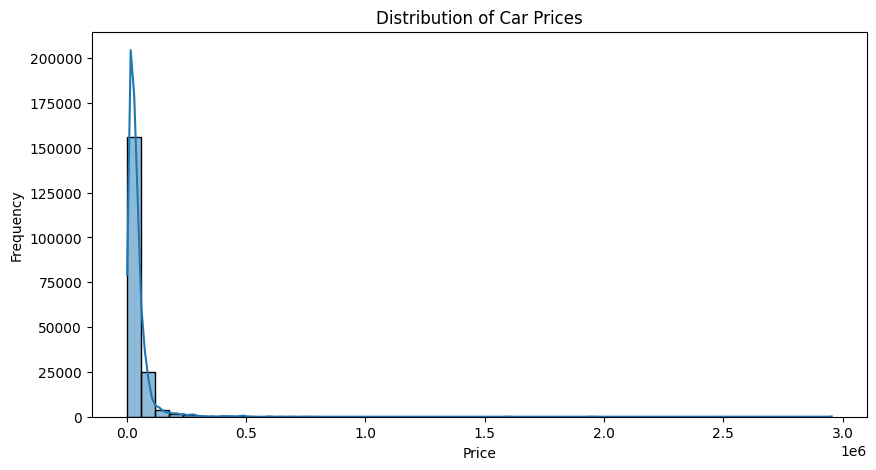

In [198]:
# Analyze target variable

print("Price Statistics:")
print(df['price'].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df['price'], bins=50, kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

In [199]:
# Number of unique values in each categorical column

for col in categorical_cols:
    print(col, ":", df[col].nunique())

brand : 57
model : 1897
fuel_type : 7
engine : 1117
transmission : 52
ext_col : 319
int_col : 156
accident : 2
clean_title : 1


In [200]:
# Create a copy of the dataset
df = df.copy()

# Remove unnecessary ID column
df = df.drop(columns=['id'])

print("ID column removed successfully!")
print("New dataset shape:", df.shape)

ID column removed successfully!
New dataset shape: (188533, 12)


In [201]:
# Get categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# Remove unnecessary whitespace
for col in categorical_cols:
    df[col] = df[col].str.strip()

# Convert empty strings into missing values
df[categorical_cols] = df[categorical_cols].replace(r'^\s*$', np.nan, regex=True)

print("Categorical values cleaned successfully!")

Categorical values cleaned successfully!


In [202]:
# Fill missing categorical values
for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")

print("Missing categorical values handled!")

Missing categorical values handled!


In [203]:
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

Missing values after cleaning:
brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64

Dataset shape:
(188533, 12)

First 5 rows:


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500


In [204]:
# Separate features and target

X = df.drop(columns=['price'])
y = df['price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Features shape: (188533, 11)
Target shape: (188533,)

Features:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


In [205]:
# First split: 70% training, 30% temporary

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Second split: 15% validation, 15% testing

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (131973, 11)
Validation set: (28280, 11)
Testing set: (28280, 11)


In [206]:
# Calculate dataset percentages

total = len(df)

print("Training:", round(len(X_train) / total * 100, 2), "%")
print("Validation:", round(len(X_val) / total * 100, 2), "%")
print("Testing:", round(len(X_test) / total * 100, 2), "%")

Training: 70.0 %
Validation: 15.0 %
Testing: 15.0 %


In [207]:
#Apply One-Hot Encoding

from sklearn.preprocessing import OneHotEncoder

# Identify categorical features
categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Categorical features:")
print(categorical_features)

# Create the encoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    max_categories=50,
    sparse_output=False
)

# Fit on training data and transform all datasets
X_train_cat = encoder.fit_transform(
    X_train[categorical_features]
)

X_val_cat = encoder.transform(
    X_val[categorical_features]
)

X_test_cat = encoder.transform(
    X_test[categorical_features]
)

# Convert to float32
X_train_cat = X_train_cat.astype(np.float32)
X_val_cat = X_val_cat.astype(np.float32)
X_test_cat = X_test_cat.astype(np.float32)

print("\nEncoding completed successfully!")

print("Training categorical shape:", X_train_cat.shape)
print("Validation categorical shape:", X_val_cat.shape)
print("Testing categorical shape:", X_test_cat.shape)

print("\nTotal encoded features:", X_train_cat.shape[1])

Categorical features:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']

Encoding completed successfully!
Training categorical shape: (131973, 313)
Validation categorical shape: (28280, 313)
Testing categorical shape: (28280, 313)

Total encoded features: 313


In [208]:
#Import and create the scaler

from sklearn.preprocessing import StandardScaler

# Identify numerical features
numerical_features = ['model_year', 'milage']

# Create the scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_num = scaler.fit_transform(
    X_train[numerical_features]
)

# Transform validation and testing data
X_val_num = scaler.transform(
    X_val[numerical_features]
)

X_test_num = scaler.transform(
    X_test[numerical_features]
)

print("Numerical scaling completed!")

print("Training numerical shape:", X_train_num.shape)
print("Validation numerical shape:", X_val_num.shape)
print("Testing numerical shape:", X_test_num.shape)

Numerical scaling completed!
Training numerical shape: (131973, 2)
Validation numerical shape: (28280, 2)
Testing numerical shape: (28280, 2)


In [209]:
print("Training numerical means:")
print(X_train_num.mean(axis=0))

print("\nTraining numerical standard deviations:")
print(X_train_num.std(axis=0))

Training numerical means:
[7.73228657e-15 7.90371315e-17]

Training numerical standard deviations:
[1. 1.]


In [210]:
# Combine numerical and categorical features

X_train_final = np.concatenate(
    [X_train_num, X_train_cat], axis=1
)

X_val_final = np.concatenate(
    [X_val_num, X_val_cat], axis=1
)

X_test_final = np.concatenate(
    [X_test_num, X_test_cat], axis=1
)

print("Final feature shapes:")

print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Testing:", X_test_final.shape)

Final feature shapes:
Training: (131973, 315)
Validation: (28280, 315)
Testing: (28280, 315)


In [211]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create target scaler
target_scaler = StandardScaler()

# Fit on training prices only
y_train_scaled = target_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

# Transform validation and testing prices
y_val_scaled = target_scaler.transform(
    y_val.to_numpy().reshape(-1, 1)
)

y_test_scaled = target_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
)

print("Target scaling completed!")
print("Training target mean:", y_train_scaled.mean())
print("Training target std:", y_train_scaled.std())

Target scaling completed!
Training target mean: 9.475841383751042e-18
Training target std: 1.0


In [212]:
# Convert features to float32
X_train_final = X_train_final.astype(np.float32)
X_val_final = X_val_final.astype(np.float32)
X_test_final = X_test_final.astype(np.float32)

# Convert features to PyTorch tensors
X_train_tensor = torch.tensor(X_train_final, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_final, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_final, dtype=torch.float32)

# Convert targets to PyTorch tensors
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)

print("PyTorch tensors created successfully!")

PyTorch tensors created successfully!


In [213]:
print("Training features:", X_train_tensor.shape)
print("Training target:", y_train_tensor.shape)

print("Validation features:", X_val_tensor.shape)
print("Validation target:", y_val_tensor.shape)

print("Testing features:", X_test_tensor.shape)
print("Testing target:", y_test_tensor.shape)

Training features: torch.Size([131973, 315])
Training target: torch.Size([131973, 1])
Validation features: torch.Size([28280, 315])
Validation target: torch.Size([28280, 1])
Testing features: torch.Size([28280, 315])
Testing target: torch.Size([28280, 1])


In [214]:
# STEP 2: BASELINE MODELS

In [215]:
## 1. Linear Regression Baseline
# Define Linear Regression model

class LinearRegressionModel(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.linear = nn.Linear(input_size, 1)

    def forward(self, x):
        return self.linear(x)


# Create the model
linear_model = LinearRegressionModel(input_size=315)

print(linear_model)

LinearRegressionModel(
  (linear): Linear(in_features=315, out_features=1, bias=True)
)


In [216]:
from torch.utils.data import TensorDataset, DataLoader

# Create training dataset
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Create DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
optimizer = optim.Adam(
    linear_model.parameters(),
    lr=0.01
)

# Number of epochs
epochs = 30

print("Training setup completed!")

Training setup completed!


In [217]:
# Store training and validation losses
linear_train_losses = []
linear_val_losses = []

for epoch in range(epochs):

    # Training mode
    linear_model.train()

    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        # Forward pass
        predictions = linear_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation mode
    linear_model.eval()

    with torch.no_grad():

        val_predictions = linear_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    linear_train_losses.append(train_loss)
    linear_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Linear Regression training completed!")

Epoch [1/30], Train Loss: 0.8932, Val Loss: 0.7096
Epoch [2/30], Train Loss: 0.8882, Val Loss: 0.7106
Epoch [3/30], Train Loss: 0.8888, Val Loss: 0.7093
Epoch [4/30], Train Loss: 0.8885, Val Loss: 0.7033
Epoch [5/30], Train Loss: 0.8884, Val Loss: 0.7077
Epoch [6/30], Train Loss: 0.8888, Val Loss: 0.7072
Epoch [7/30], Train Loss: 0.8885, Val Loss: 0.7052
Epoch [8/30], Train Loss: 0.8885, Val Loss: 0.7045
Epoch [9/30], Train Loss: 0.8890, Val Loss: 0.7042
Epoch [10/30], Train Loss: 0.8889, Val Loss: 0.7037
Epoch [11/30], Train Loss: 0.8881, Val Loss: 0.7083
Epoch [12/30], Train Loss: 0.8883, Val Loss: 0.7064
Epoch [13/30], Train Loss: 0.8883, Val Loss: 0.7078
Epoch [14/30], Train Loss: 0.8882, Val Loss: 0.7079
Epoch [15/30], Train Loss: 0.8880, Val Loss: 0.7091
Epoch [16/30], Train Loss: 0.8884, Val Loss: 0.7087
Epoch [17/30], Train Loss: 0.8885, Val Loss: 0.7102
Epoch [18/30], Train Loss: 0.8889, Val Loss: 0.7049
Epoch [19/30], Train Loss: 0.8879, Val Loss: 0.7055
Epoch [20/30], Train 

In [218]:
# Convert predictions back to original price scale

linear_model.eval()

with torch.no_grad():

    train_pred_scaled = linear_model(X_train_tensor).numpy()
    val_pred_scaled = linear_model(X_val_tensor).numpy()

    train_predictions = target_scaler.inverse_transform(
        train_pred_scaled
    )

    val_predictions = target_scaler.inverse_transform(
        val_pred_scaled
    )

# Calculate MSE
linear_train_mse = mean_squared_error(
    y_train,
    train_predictions
)

linear_val_mse = mean_squared_error(
    y_val,
    val_predictions
)

print("Linear Regression Results")
print("--------------------------")
print("Training MSE:", linear_train_mse)
print("Validation MSE:", linear_val_mse)


Linear Regression Results
--------------------------
Training MSE: 5855106048.0
Validation MSE: 4687364096.0


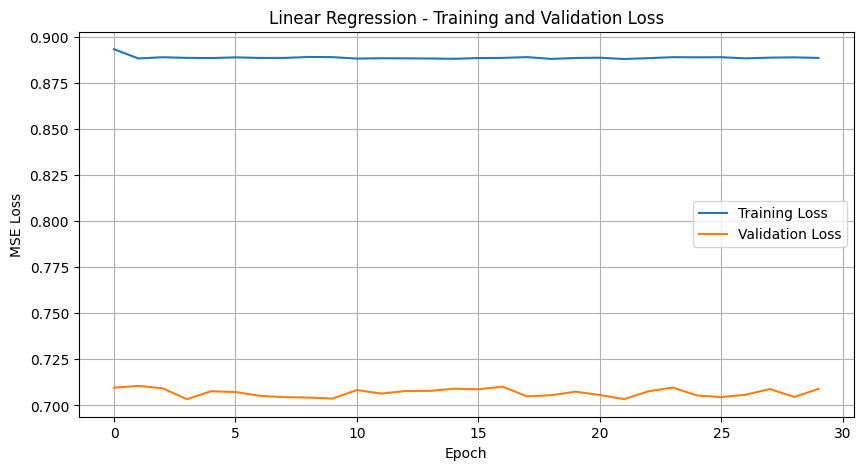

In [219]:
plt.figure(figsize=(10, 5))

plt.plot(
    linear_train_losses,
    label="Training Loss"
)

plt.plot(
    linear_val_losses,
    label="Validation Loss"
)

plt.title("Linear Regression - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.show()

In [220]:
# 2. Deep Neural Network Baseline
# Define Deep Neural Network

class DeepNeuralNetwork(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model
dnn_model = DeepNeuralNetwork(input_size=315)

print(dnn_model)

DeepNeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [221]:
# Create DataLoader for DNN

dnn_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
dnn_optimizer = optim.Adam(
    dnn_model.parameters(),
    lr=0.001
)

# Number of epochs
epochs = 30

print("DNN training setup completed!")

DNN training setup completed!


In [222]:
# Store training and validation losses

dnn_train_losses = []
dnn_val_losses = []

for epoch in range(epochs):

    dnn_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = dnn_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        dnn_optimizer.zero_grad()

        loss.backward()

        dnn_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    dnn_model.eval()

    with torch.no_grad():

        val_predictions = dnn_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    dnn_train_losses.append(train_loss)
    dnn_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("DNN training completed!")

Epoch [1/30], Train Loss: 0.8838, Val Loss: 0.6885
Epoch [2/30], Train Loss: 0.8679, Val Loss: 0.6822
Epoch [3/30], Train Loss: 0.8632, Val Loss: 0.6824
Epoch [4/30], Train Loss: 0.8602, Val Loss: 0.6819
Epoch [5/30], Train Loss: 0.8562, Val Loss: 0.6882
Epoch [6/30], Train Loss: 0.8531, Val Loss: 0.6853
Epoch [7/30], Train Loss: 0.8483, Val Loss: 0.6881
Epoch [8/30], Train Loss: 0.8436, Val Loss: 0.6983
Epoch [9/30], Train Loss: 0.8394, Val Loss: 0.6937
Epoch [10/30], Train Loss: 0.8287, Val Loss: 0.6926
Epoch [11/30], Train Loss: 0.8221, Val Loss: 0.6974
Epoch [12/30], Train Loss: 0.8086, Val Loss: 0.7217
Epoch [13/30], Train Loss: 0.7882, Val Loss: 0.7400
Epoch [14/30], Train Loss: 0.7694, Val Loss: 0.7532
Epoch [15/30], Train Loss: 0.7538, Val Loss: 0.7164
Epoch [16/30], Train Loss: 0.7376, Val Loss: 0.7061
Epoch [17/30], Train Loss: 0.7156, Val Loss: 0.7535
Epoch [18/30], Train Loss: 0.7047, Val Loss: 0.7110
Epoch [19/30], Train Loss: 0.6901, Val Loss: 0.7274
Epoch [20/30], Train 

In [223]:
# Evaluate DNN

dnn_model.eval()

with torch.no_grad():

    train_pred_scaled = dnn_model(X_train_tensor).numpy()

    val_pred_scaled = dnn_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    train_predictions = target_scaler.inverse_transform(
        train_pred_scaled
    )

    val_predictions = target_scaler.inverse_transform(
        val_pred_scaled
    )

# Calculate MSE
dnn_train_mse = mean_squared_error(
    y_train,
    train_predictions
)

dnn_val_mse = mean_squared_error(
    y_val,
    val_predictions
)

print("Deep Neural Network Results")
print("---------------------------")

print("Training MSE:", dnn_train_mse)

print("Validation MSE:", dnn_val_mse)

Deep Neural Network Results
---------------------------
Training MSE: 3745821184.0
Validation MSE: 5152241664.0


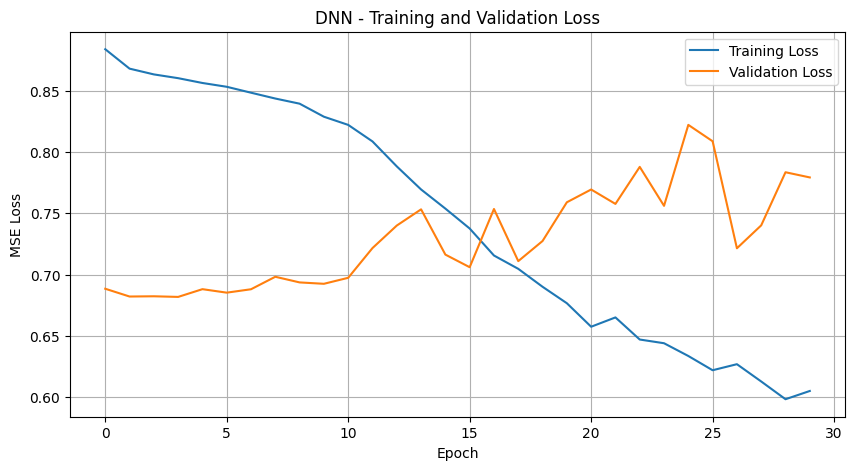

In [224]:
plt.figure(figsize=(10, 5))

plt.plot(
    dnn_train_losses,
    label="Training Loss"
)

plt.plot(
    dnn_val_losses,
    label="Validation Loss"
)

plt.title("DNN - Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("MSE Loss")

plt.legend()

plt.grid(True)

plt.show()

In [225]:
# 3. Baseline Model Comparison
# Compare baseline models

comparison = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Deep Neural Network"
    ],

    "Training MSE": [
        linear_train_mse,
        dnn_train_mse
    ],

    "Validation MSE": [
        linear_val_mse,
        dnn_val_mse
    ]

})

display(comparison)

,Model,Training MSE,Validation MSE
0,Linear Regression,5.855106e+09,4.687364e+09
1,Deep Neural Network,3.745821e+09,5.152242e+09


In [226]:
# EXPERIMENT 1 - LEARNING RATE 0.00001

# Create a fresh DNN model
exp1_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.00001
exp1_optimizer = optim.Adam(
    exp1_model.parameters(),
    lr=0.00001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp1_train_losses = []
exp1_val_losses = []

print("Experiment 1 setup completed!")

Experiment 1 setup completed!


In [227]:
# EXPERIMENT 1 - TRAIN MODEL

for epoch in range(30):

    # Set model to training mode
    exp1_model.train()

    total_train_loss = 0

    # Loop through training batches
    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp1_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp1_optimizer.zero_grad()

        loss.backward()

        exp1_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp1_model.eval()

    with torch.no_grad():

        val_predictions = exp1_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp1_train_losses.append(train_loss)
    exp1_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 1 completed!")

Epoch [1/30], Train Loss: 0.9939, Val Loss: 0.8033
Epoch [2/30], Train Loss: 0.9754, Val Loss: 0.7766
Epoch [3/30], Train Loss: 0.9443, Val Loss: 0.7433
Epoch [4/30], Train Loss: 0.9189, Val Loss: 0.7257
Epoch [5/30], Train Loss: 0.9072, Val Loss: 0.7175
Epoch [6/30], Train Loss: 0.9004, Val Loss: 0.7122
Epoch [7/30], Train Loss: 0.8954, Val Loss: 0.7080
Epoch [8/30], Train Loss: 0.8914, Val Loss: 0.7048
Epoch [9/30], Train Loss: 0.8880, Val Loss: 0.7018
Epoch [10/30], Train Loss: 0.8850, Val Loss: 0.6993
Epoch [11/30], Train Loss: 0.8825, Val Loss: 0.6972
Epoch [12/30], Train Loss: 0.8804, Val Loss: 0.6955
Epoch [13/30], Train Loss: 0.8786, Val Loss: 0.6940
Epoch [14/30], Train Loss: 0.8769, Val Loss: 0.6928
Epoch [15/30], Train Loss: 0.8755, Val Loss: 0.6917
Epoch [16/30], Train Loss: 0.8742, Val Loss: 0.6908
Epoch [17/30], Train Loss: 0.8732, Val Loss: 0.6898
Epoch [18/30], Train Loss: 0.8721, Val Loss: 0.6890
Epoch [19/30], Train Loss: 0.8712, Val Loss: 0.6883
Epoch [20/30], Train 

In [228]:
# EXPERIMENT 1 - EVALUATE MODEL

exp1_model.eval()

with torch.no_grad():

    exp1_val_scaled = exp1_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp1_val_predictions = target_scaler.inverse_transform(
        exp1_val_scaled
    )

# Calculate validation MSE
exp1_val_mse = mean_squared_error(
    y_val,
    exp1_val_predictions
)

print("Experiment 1 Validation MSE:", exp1_val_mse)

Experiment 1 Validation MSE: 4524390912.0


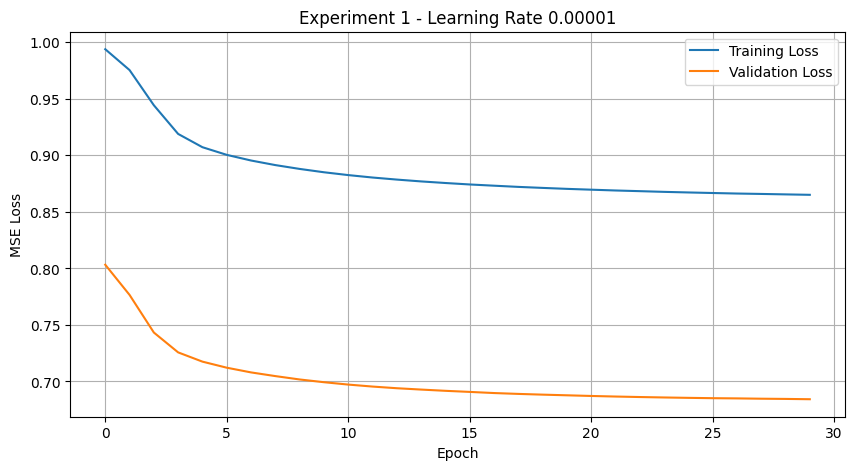

In [229]:
# EXPERIMENT 1 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp1_train_losses,
    label="Training Loss"
)

plt.plot(
    exp1_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 1 - Learning Rate 0.00001")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [230]:
# EXPERIMENT 2 - LEARNING RATE 0.0001

# Create a fresh DNN model
exp2_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.0001
exp2_optimizer = optim.Adam(
    exp2_model.parameters(),
    lr=0.0001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp2_train_losses = []
exp2_val_losses = []

print("Experiment 2 setup completed!")

Experiment 2 setup completed!


In [231]:
# EXPERIMENT 2 - TRAIN MODEL

for epoch in range(30):

    exp2_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp2_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp2_optimizer.zero_grad()

        loss.backward()

        exp2_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp2_model.eval()

    with torch.no_grad():

        val_predictions = exp2_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp2_train_losses.append(train_loss)
    exp2_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 2 completed!")

Epoch [1/30], Train Loss: 0.9225, Val Loss: 0.6978
Epoch [2/30], Train Loss: 0.8755, Val Loss: 0.6868
Epoch [3/30], Train Loss: 0.8676, Val Loss: 0.6830
Epoch [4/30], Train Loss: 0.8639, Val Loss: 0.6814
Epoch [5/30], Train Loss: 0.8617, Val Loss: 0.6824
Epoch [6/30], Train Loss: 0.8601, Val Loss: 0.6812
Epoch [7/30], Train Loss: 0.8590, Val Loss: 0.6816
Epoch [8/30], Train Loss: 0.8581, Val Loss: 0.6822
Epoch [9/30], Train Loss: 0.8566, Val Loss: 0.6822
Epoch [10/30], Train Loss: 0.8555, Val Loss: 0.6816
Epoch [11/30], Train Loss: 0.8547, Val Loss: 0.6820
Epoch [12/30], Train Loss: 0.8532, Val Loss: 0.6818
Epoch [13/30], Train Loss: 0.8522, Val Loss: 0.6841
Epoch [14/30], Train Loss: 0.8510, Val Loss: 0.6825
Epoch [15/30], Train Loss: 0.8501, Val Loss: 0.6835
Epoch [16/30], Train Loss: 0.8486, Val Loss: 0.6839
Epoch [17/30], Train Loss: 0.8474, Val Loss: 0.6835
Epoch [18/30], Train Loss: 0.8461, Val Loss: 0.6836
Epoch [19/30], Train Loss: 0.8448, Val Loss: 0.6836
Epoch [20/30], Train 

In [232]:
# EXPERIMENT 2 - EVALUATE MODEL

exp2_model.eval()

with torch.no_grad():

    exp2_val_scaled = exp2_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp2_val_predictions = target_scaler.inverse_transform(
        exp2_val_scaled
    )

# Calculate validation MSE
exp2_val_mse = mean_squared_error(
    y_val,
    exp2_val_predictions
)

print("Experiment 2 Validation MSE:", exp2_val_mse)

Experiment 2 Validation MSE: 4582242304.0


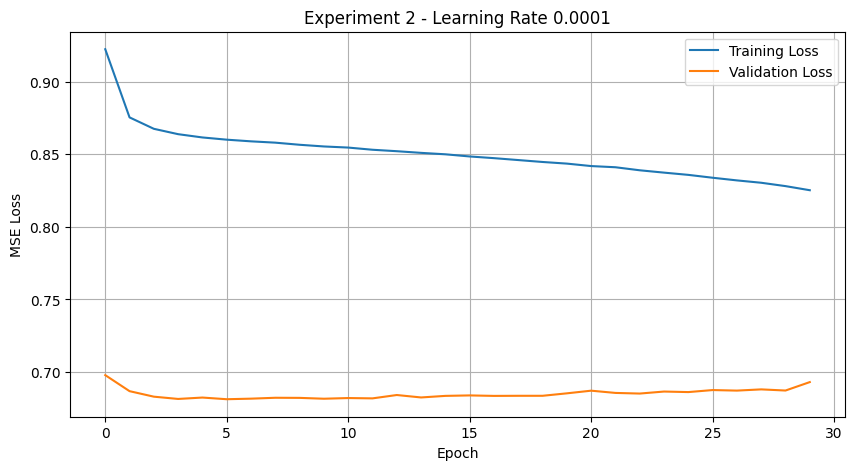

In [233]:
# EXPERIMENT 2 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp2_train_losses,
    label="Training Loss"
)

plt.plot(
    exp2_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 2 - Learning Rate 0.0001")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [234]:
# EXPERIMENT 3 - LEARNING RATE 0.0005

# Create a fresh DNN model
exp3_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.0005
exp3_optimizer = optim.Adam(
    exp3_model.parameters(),
    lr=0.0005
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp3_train_losses = []
exp3_val_losses = []

print("Experiment 3 setup completed!")

Experiment 3 setup completed!


In [235]:
# EXPERIMENT 3 - TRAIN MODEL

for epoch in range(30):

    exp3_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp3_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp3_optimizer.zero_grad()

        loss.backward()

        exp3_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp3_model.eval()

    with torch.no_grad():

        val_predictions = exp3_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp3_train_losses.append(train_loss)
    exp3_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 3 completed!")

Epoch [1/30], Train Loss: 0.8868, Val Loss: 0.6915
Epoch [2/30], Train Loss: 0.8659, Val Loss: 0.6821
Epoch [3/30], Train Loss: 0.8612, Val Loss: 0.6861
Epoch [4/30], Train Loss: 0.8581, Val Loss: 0.6859
Epoch [5/30], Train Loss: 0.8538, Val Loss: 0.6874
Epoch [6/30], Train Loss: 0.8509, Val Loss: 0.6876
Epoch [7/30], Train Loss: 0.8455, Val Loss: 0.6920
Epoch [8/30], Train Loss: 0.8394, Val Loss: 0.6897
Epoch [9/30], Train Loss: 0.8339, Val Loss: 0.6973
Epoch [10/30], Train Loss: 0.8248, Val Loss: 0.7037
Epoch [11/30], Train Loss: 0.8159, Val Loss: 0.7203
Epoch [12/30], Train Loss: 0.8002, Val Loss: 0.6977
Epoch [13/30], Train Loss: 0.7812, Val Loss: 0.7068
Epoch [14/30], Train Loss: 0.7742, Val Loss: 0.7496
Epoch [15/30], Train Loss: 0.7518, Val Loss: 0.7010
Epoch [16/30], Train Loss: 0.7329, Val Loss: 0.7188
Epoch [17/30], Train Loss: 0.7147, Val Loss: 0.7843
Epoch [18/30], Train Loss: 0.7031, Val Loss: 0.7145
Epoch [19/30], Train Loss: 0.6895, Val Loss: 0.7962
Epoch [20/30], Train 

In [236]:
# EXPERIMENT 3 - EVALUATE MODEL

exp3_model.eval()

with torch.no_grad():

    exp3_val_scaled = exp3_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp3_val_predictions = target_scaler.inverse_transform(
        exp3_val_scaled
    )

# Calculate validation MSE
exp3_val_mse = mean_squared_error(
    y_val,
    exp3_val_predictions
)

print("Experiment 3 Validation MSE:", exp3_val_mse)

Experiment 3 Validation MSE: 4807088128.0


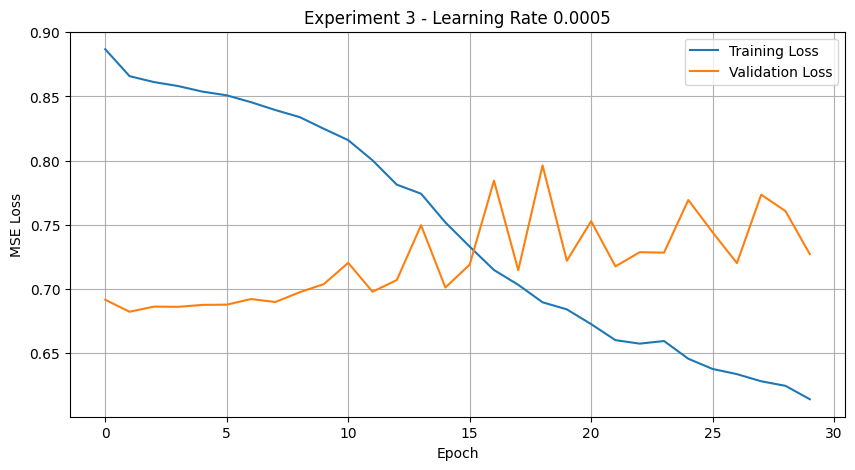

In [237]:
# EXPERIMENT 3 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp3_train_losses,
    label="Training Loss"
)

plt.plot(
    exp3_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 3 - Learning Rate 0.0005")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [238]:
# EXPERIMENT 4 - LEARNING RATE 0.001

# Create a fresh DNN model
exp4_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.001
exp4_optimizer = optim.Adam(
    exp4_model.parameters(),
    lr=0.001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp4_train_losses = []
exp4_val_losses = []

print("Experiment 4 setup completed!")

Experiment 4 setup completed!


In [239]:
# EXPERIMENT 4 - TRAIN MODEL

for epoch in range(30):

    exp4_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp4_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp4_optimizer.zero_grad()

        loss.backward()

        exp4_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp4_model.eval()

    with torch.no_grad():

        val_predictions = exp4_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp4_train_losses.append(train_loss)
    exp4_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 4 completed!")

Epoch [1/30], Train Loss: 0.8817, Val Loss: 0.6828
Epoch [2/30], Train Loss: 0.8658, Val Loss: 0.6841
Epoch [3/30], Train Loss: 0.8618, Val Loss: 0.6871
Epoch [4/30], Train Loss: 0.8595, Val Loss: 0.6848
Epoch [5/30], Train Loss: 0.8555, Val Loss: 0.6849
Epoch [6/30], Train Loss: 0.8509, Val Loss: 0.7036
Epoch [7/30], Train Loss: 0.8465, Val Loss: 0.6868
Epoch [8/30], Train Loss: 0.8405, Val Loss: 0.6908
Epoch [9/30], Train Loss: 0.8317, Val Loss: 0.7105
Epoch [10/30], Train Loss: 0.8234, Val Loss: 0.6947
Epoch [11/30], Train Loss: 0.8069, Val Loss: 0.6973
Epoch [12/30], Train Loss: 0.7861, Val Loss: 0.7036
Epoch [13/30], Train Loss: 0.7692, Val Loss: 0.6978
Epoch [14/30], Train Loss: 0.7423, Val Loss: 0.7116
Epoch [15/30], Train Loss: 0.7236, Val Loss: 0.7503
Epoch [16/30], Train Loss: 0.6976, Val Loss: 0.7056
Epoch [17/30], Train Loss: 0.6951, Val Loss: 0.7149
Epoch [18/30], Train Loss: 0.6750, Val Loss: 0.7063
Epoch [19/30], Train Loss: 0.6620, Val Loss: 0.7459
Epoch [20/30], Train 

In [240]:
# EXPERIMENT 4 - EVALUATE MODEL

exp4_model.eval()

with torch.no_grad():

    exp4_val_scaled = exp4_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp4_val_predictions = target_scaler.inverse_transform(
        exp4_val_scaled
    )

# Calculate validation MSE
exp4_val_mse = mean_squared_error(
    y_val,
    exp4_val_predictions
)

print("Experiment 4 Validation MSE:", exp4_val_mse)

Experiment 4 Validation MSE: 4850209792.0


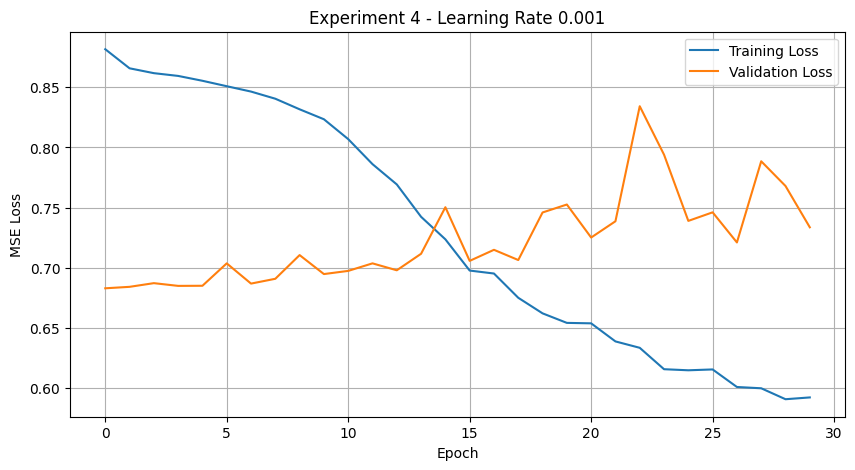

In [241]:
# EXPERIMENT 4 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp4_train_losses,
    label="Training Loss"
)

plt.plot(
    exp4_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 4 - Learning Rate 0.001")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [242]:
# EXPERIMENT 5 - LEARNING RATE 0.01

# Create a fresh DNN model
exp5_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.01
exp5_optimizer = optim.Adam(
    exp5_model.parameters(),
    lr=0.01
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp5_train_losses = []
exp5_val_losses = []

print("Experiment 5 setup completed!")

Experiment 5 setup completed!


In [243]:
# EXPERIMENT 5 - TRAIN MODEL

for epoch in range(30):

    exp5_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp5_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp5_optimizer.zero_grad()

        loss.backward()

        exp5_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp5_model.eval()

    with torch.no_grad():

        val_predictions = exp5_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp5_train_losses.append(train_loss)
    exp5_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 5 completed!")

Epoch [1/30], Train Loss: 0.8825, Val Loss: 0.7066
Epoch [2/30], Train Loss: 0.8716, Val Loss: 0.6860
Epoch [3/30], Train Loss: 0.8669, Val Loss: 0.6950
Epoch [4/30], Train Loss: 0.8642, Val Loss: 0.7014
Epoch [5/30], Train Loss: 0.8638, Val Loss: 0.6870
Epoch [6/30], Train Loss: 0.8560, Val Loss: 0.6916
Epoch [7/30], Train Loss: 0.8495, Val Loss: 0.7066
Epoch [8/30], Train Loss: 0.8455, Val Loss: 0.7029
Epoch [9/30], Train Loss: 0.8448, Val Loss: 0.6887
Epoch [10/30], Train Loss: 0.8484, Val Loss: 0.6993
Epoch [11/30], Train Loss: 0.8241, Val Loss: 0.6968
Epoch [12/30], Train Loss: 0.8200, Val Loss: 0.6976
Epoch [13/30], Train Loss: 0.8352, Val Loss: 0.6867
Epoch [14/30], Train Loss: 0.8255, Val Loss: 0.7017
Epoch [15/30], Train Loss: 0.8239, Val Loss: 0.6959
Epoch [16/30], Train Loss: 0.8198, Val Loss: 0.7247
Epoch [17/30], Train Loss: 0.8143, Val Loss: 0.6934
Epoch [18/30], Train Loss: 0.8055, Val Loss: 0.6956
Epoch [19/30], Train Loss: 0.7980, Val Loss: 0.7104
Epoch [20/30], Train 

In [244]:
# EXPERIMENT 5 - EVALUATE MODEL

exp5_model.eval()

with torch.no_grad():

    exp5_val_scaled = exp5_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp5_val_predictions = target_scaler.inverse_transform(
        exp5_val_scaled
    )

# Calculate validation MSE
exp5_val_mse = mean_squared_error(
    y_val,
    exp5_val_predictions
)

print("Experiment 5 Validation MSE:", exp5_val_mse)

Experiment 5 Validation MSE: 4850358784.0


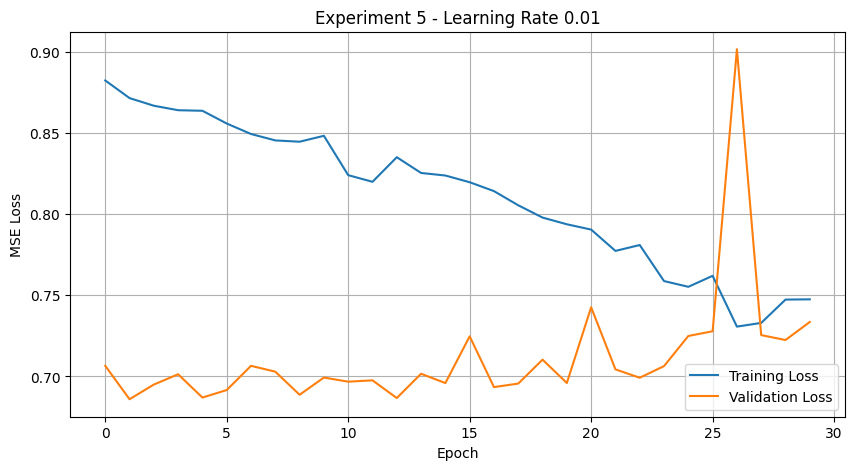

In [245]:
# EXPERIMENT 5 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp5_train_losses,
    label="Training Loss"
)

plt.plot(
    exp5_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 5 - Learning Rate 0.01")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [246]:
# EXPERIMENT 6 - LEARNING RATE 0.1

# Create a fresh DNN model
exp6_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.1
exp6_optimizer = optim.Adam(
    exp6_model.parameters(),
    lr=0.1
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp6_train_losses = []
exp6_val_losses = []

print("Experiment 6 setup completed!")

Experiment 6 setup completed!


In [247]:
# EXPERIMENT 6 - TRAIN MODEL

for epoch in range(30):

    exp6_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp6_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp6_optimizer.zero_grad()

        loss.backward()

        exp6_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp6_model.eval()

    with torch.no_grad():

        val_predictions = exp6_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp6_train_losses.append(train_loss)
    exp6_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 6 completed!")

Epoch [1/30], Train Loss: 2.5129, Val Loss: 0.8652
Epoch [2/30], Train Loss: 1.0013, Val Loss: 0.8169
Epoch [3/30], Train Loss: 1.0009, Val Loss: 0.8165
Epoch [4/30], Train Loss: 1.0007, Val Loss: 0.8185
Epoch [5/30], Train Loss: 1.0006, Val Loss: 0.8170
Epoch [6/30], Train Loss: 1.0007, Val Loss: 0.8193
Epoch [7/30], Train Loss: 1.0011, Val Loss: 0.8182
Epoch [8/30], Train Loss: 1.0016, Val Loss: 0.8216
Epoch [9/30], Train Loss: 1.0015, Val Loss: 0.8188
Epoch [10/30], Train Loss: 1.0028, Val Loss: 0.8164
Epoch [11/30], Train Loss: 1.0016, Val Loss: 0.8192
Epoch [12/30], Train Loss: 1.0020, Val Loss: 0.8167
Epoch [13/30], Train Loss: 1.0021, Val Loss: 0.8192
Epoch [14/30], Train Loss: 1.0035, Val Loss: 0.8175
Epoch [15/30], Train Loss: 1.0018, Val Loss: 0.8168
Epoch [16/30], Train Loss: 1.0028, Val Loss: 0.8182
Epoch [17/30], Train Loss: 1.0017, Val Loss: 0.8165
Epoch [18/30], Train Loss: 1.0024, Val Loss: 0.8401
Epoch [19/30], Train Loss: 1.0028, Val Loss: 0.8166
Epoch [20/30], Train 

In [248]:
# EXPERIMENT 6 - EVALUATE MODEL

exp6_model.eval()

with torch.no_grad():

    exp6_val_scaled = exp6_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp6_val_predictions = target_scaler.inverse_transform(
        exp6_val_scaled
    )

# Calculate validation MSE
exp6_val_mse = mean_squared_error(
    y_val,
    exp6_val_predictions
)

print("Experiment 6 Validation MSE:", exp6_val_mse)

Experiment 6 Validation MSE: 5401464832.0


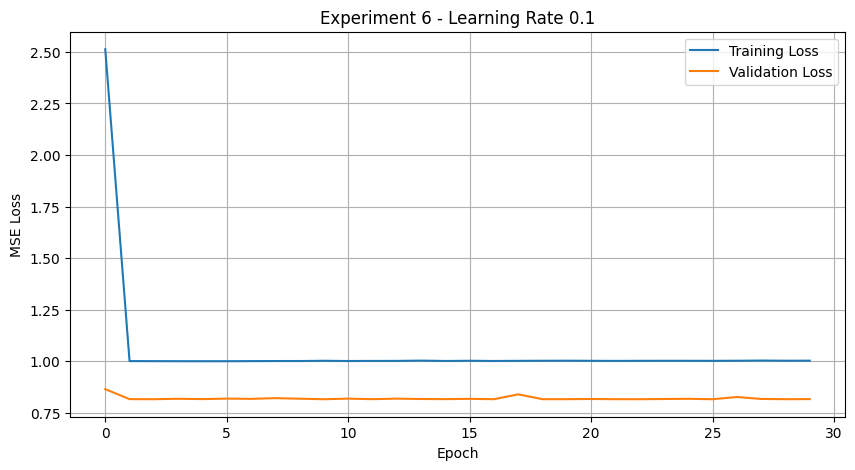

In [249]:
# EXPERIMENT 6 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp6_train_losses,
    label="Training Loss"
)

plt.plot(
    exp6_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 6 - Learning Rate 0.1")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [250]:
# EXPERIMENT 7 - ADAM OPTIMIZER

# Create a fresh DNN model
exp7_model = DeepNeuralNetwork(input_size=315)

# Define Adam optimizer
exp7_optimizer = optim.Adam(
    exp7_model.parameters(),
    lr=0.001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp7_train_losses = []
exp7_val_losses = []

print("Experiment 7 setup completed!")

Experiment 7 setup completed!


In [251]:
# EXPERIMENT 7 - TRAIN MODEL

for epoch in range(30):

    exp7_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp7_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp7_optimizer.zero_grad()

        loss.backward()

        exp7_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp7_model.eval()

    with torch.no_grad():

        val_predictions = exp7_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp7_train_losses.append(train_loss)
    exp7_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 7 completed!")

Epoch [1/30], Train Loss: 0.8818, Val Loss: 0.6851
Epoch [2/30], Train Loss: 0.8666, Val Loss: 0.6833
Epoch [3/30], Train Loss: 0.8627, Val Loss: 0.6835
Epoch [4/30], Train Loss: 0.8585, Val Loss: 0.6866
Epoch [5/30], Train Loss: 0.8553, Val Loss: 0.6849
Epoch [6/30], Train Loss: 0.8518, Val Loss: 0.6940
Epoch [7/30], Train Loss: 0.8465, Val Loss: 0.6853
Epoch [8/30], Train Loss: 0.8399, Val Loss: 0.6907
Epoch [9/30], Train Loss: 0.8335, Val Loss: 0.7069
Epoch [10/30], Train Loss: 0.8229, Val Loss: 0.6995
Epoch [11/30], Train Loss: 0.7991, Val Loss: 0.6881
Epoch [12/30], Train Loss: 0.7990, Val Loss: 0.6994
Epoch [13/30], Train Loss: 0.7582, Val Loss: 0.6992
Epoch [14/30], Train Loss: 0.7514, Val Loss: 0.7316
Epoch [15/30], Train Loss: 0.7165, Val Loss: 0.7101
Epoch [16/30], Train Loss: 0.7217, Val Loss: 0.7702
Epoch [17/30], Train Loss: 0.7183, Val Loss: 0.7516
Epoch [18/30], Train Loss: 0.6946, Val Loss: 0.7544
Epoch [19/30], Train Loss: 0.6944, Val Loss: 0.7482
Epoch [20/30], Train 

In [252]:
# EXPERIMENT 7 - EVALUATE MODEL

exp7_model.eval()

with torch.no_grad():

    exp7_val_scaled = exp7_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp7_val_predictions = target_scaler.inverse_transform(
        exp7_val_scaled
    )

# Calculate validation MSE
exp7_val_mse = mean_squared_error(
    y_val,
    exp7_val_predictions
)

print("Experiment 7 Validation MSE:", exp7_val_mse)

Experiment 7 Validation MSE: 5330863104.0


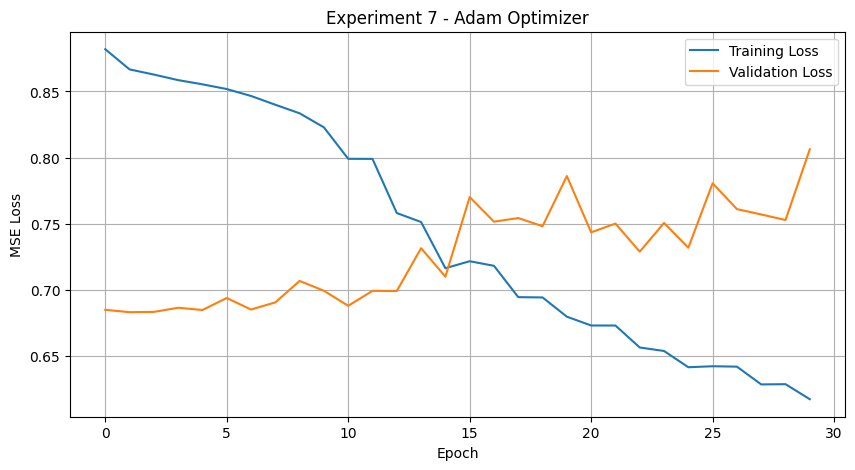

In [253]:
# EXPERIMENT 7 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp7_train_losses,
    label="Training Loss"
)

plt.plot(
    exp7_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 7 - Adam Optimizer")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [254]:
# EXPERIMENT 8 - SGD OPTIMIZER

# Create a fresh DNN model
exp8_model = DeepNeuralNetwork(input_size=315)

# Define SGD optimizer
exp8_optimizer = optim.SGD(
    exp8_model.parameters(),
    lr=0.001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp8_train_losses = []
exp8_val_losses = []

print("Experiment 8 setup completed!")

Experiment 8 setup completed!


In [255]:
# EXPERIMENT 8 - TRAIN MODEL

for epoch in range(30):

    exp8_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp8_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp8_optimizer.zero_grad()

        loss.backward()

        exp8_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp8_model.eval()

    with torch.no_grad():

        val_predictions = exp8_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp8_train_losses.append(train_loss)
    exp8_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 8 completed!")

Epoch [1/30], Train Loss: 1.0092, Val Loss: 0.8162
Epoch [2/30], Train Loss: 0.9978, Val Loss: 0.8129
Epoch [3/30], Train Loss: 0.9956, Val Loss: 0.8110
Epoch [4/30], Train Loss: 0.9936, Val Loss: 0.8088
Epoch [5/30], Train Loss: 0.9912, Val Loss: 0.8061
Epoch [6/30], Train Loss: 0.9882, Val Loss: 0.8028
Epoch [7/30], Train Loss: 0.9846, Val Loss: 0.7987
Epoch [8/30], Train Loss: 0.9802, Val Loss: 0.7937
Epoch [9/30], Train Loss: 0.9747, Val Loss: 0.7875
Epoch [10/30], Train Loss: 0.9680, Val Loss: 0.7801
Epoch [11/30], Train Loss: 0.9603, Val Loss: 0.7717
Epoch [12/30], Train Loss: 0.9517, Val Loss: 0.7626
Epoch [13/30], Train Loss: 0.9427, Val Loss: 0.7533
Epoch [14/30], Train Loss: 0.9339, Val Loss: 0.7447
Epoch [15/30], Train Loss: 0.9261, Val Loss: 0.7374
Epoch [16/30], Train Loss: 0.9199, Val Loss: 0.7318
Epoch [17/30], Train Loss: 0.9154, Val Loss: 0.7279
Epoch [18/30], Train Loss: 0.9121, Val Loss: 0.7251
Epoch [19/30], Train Loss: 0.9098, Val Loss: 0.7231
Epoch [20/30], Train 

In [256]:
# EXPERIMENT 8 - EVALUATE MODEL

exp8_model.eval()

with torch.no_grad():

    exp8_val_scaled = exp8_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp8_val_predictions = target_scaler.inverse_transform(
        exp8_val_scaled
    )

# Calculate validation MSE
exp8_val_mse = mean_squared_error(
    y_val,
    exp8_val_predictions
)

print("Experiment 8 Validation MSE:", exp8_val_mse)

Experiment 8 Validation MSE: 4712740864.0


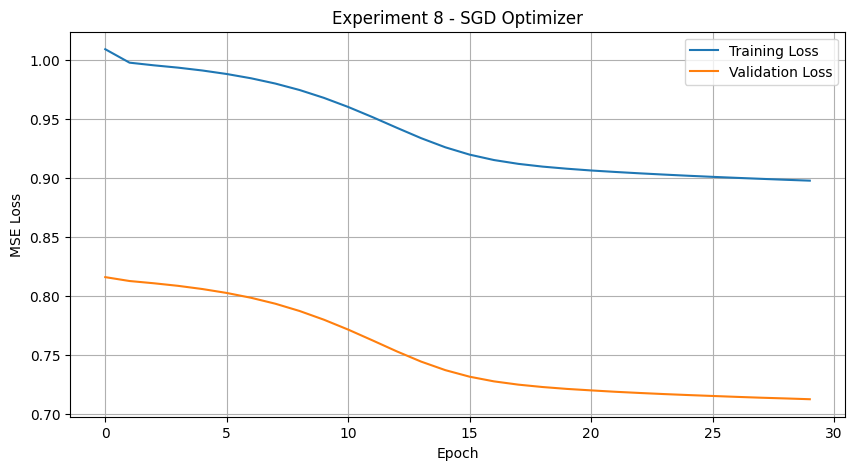

In [257]:
# EXPERIMENT 8 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp8_train_losses,
    label="Training Loss"
)

plt.plot(
    exp8_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 8 - SGD Optimizer")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [258]:
# EXPERIMENT 9 - SGD WITH MOMENTUM

# Create a fresh DNN model
exp9_model = DeepNeuralNetwork(input_size=315)

# Define SGD optimizer with Momentum
exp9_optimizer = optim.SGD(
    exp9_model.parameters(),
    lr=0.001,
    momentum=0.9
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp9_train_losses = []
exp9_val_losses = []

print("Experiment 9 setup completed!")

Experiment 9 setup completed!


In [259]:
# EXPERIMENT 9 - TRAIN MODEL

for epoch in range(30):

    exp9_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp9_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp9_optimizer.zero_grad()

        loss.backward()

        exp9_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp9_model.eval()

    with torch.no_grad():

        val_predictions = exp9_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp9_train_losses.append(train_loss)
    exp9_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 9 completed!")

Epoch [1/30], Train Loss: 0.9886, Val Loss: 0.7845
Epoch [2/30], Train Loss: 0.9329, Val Loss: 0.7267
Epoch [3/30], Train Loss: 0.9065, Val Loss: 0.7165
Epoch [4/30], Train Loss: 0.8980, Val Loss: 0.7104
Epoch [5/30], Train Loss: 0.8918, Val Loss: 0.7055
Epoch [6/30], Train Loss: 0.8872, Val Loss: 0.7011
Epoch [7/30], Train Loss: 0.8830, Val Loss: 0.6978
Epoch [8/30], Train Loss: 0.8795, Val Loss: 0.6941
Epoch [9/30], Train Loss: 0.8761, Val Loss: 0.6917
Epoch [10/30], Train Loss: 0.8738, Val Loss: 0.6892
Epoch [11/30], Train Loss: 0.8717, Val Loss: 0.6879
Epoch [12/30], Train Loss: 0.8696, Val Loss: 0.6866
Epoch [13/30], Train Loss: 0.8681, Val Loss: 0.6854
Epoch [14/30], Train Loss: 0.8669, Val Loss: 0.6844
Epoch [15/30], Train Loss: 0.8660, Val Loss: 0.6838
Epoch [16/30], Train Loss: 0.8650, Val Loss: 0.6868
Epoch [17/30], Train Loss: 0.8642, Val Loss: 0.6833
Epoch [18/30], Train Loss: 0.8638, Val Loss: 0.6833
Epoch [19/30], Train Loss: 0.8634, Val Loss: 0.6844
Epoch [20/30], Train 

In [260]:
# EXPERIMENT 9 - EVALUATE MODEL

exp9_model.eval()

with torch.no_grad():

    exp9_val_scaled = exp9_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp9_val_predictions = target_scaler.inverse_transform(
        exp9_val_scaled
    )

# Calculate validation MSE
exp9_val_mse = mean_squared_error(
    y_val,
    exp9_val_predictions
)

print("Experiment 9 Validation MSE:", exp9_val_mse)

Experiment 9 Validation MSE: 4515515392.0


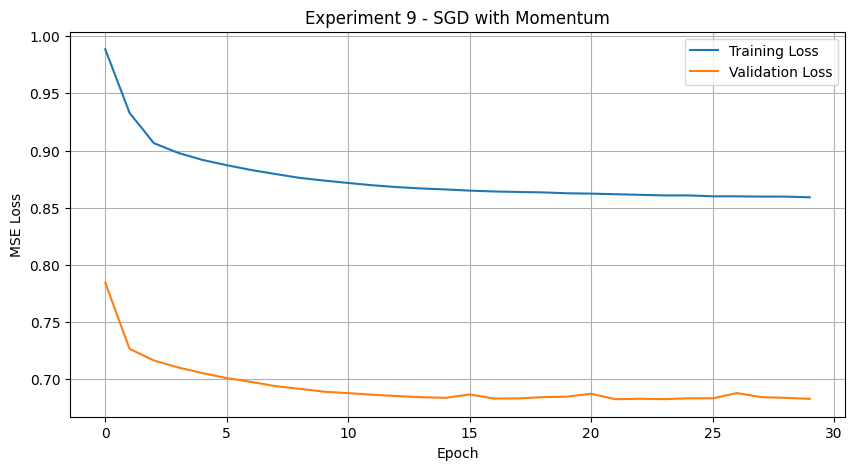

In [261]:
# EXPERIMENT 9 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp9_train_losses,
    label="Training Loss"
)

plt.plot(
    exp9_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 9 - SGD with Momentum")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [262]:
# EXPERIMENT 10 - SETUP BATCH SIZE 16

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp10_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 16
exp10_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# Define loss function
exp10_criterion = nn.MSELoss()

# Define Adam optimizer
exp10_optimizer = optim.Adam(
    exp10_model.parameters(),
    lr=0.001
)

# Initialize loss lists
exp10_train_losses = []
exp10_val_losses = []

# Number of epochs
exp10_epochs = 30

print("Experiment 10 setup completed!")

Experiment 10 setup completed!


In [263]:
# EXPERIMENT 10 - TRAIN MODEL (BATCH SIZE 16)

for epoch in range(exp10_epochs):

    # Set model to training mode
    exp10_model.train()

    total_train_loss = 0

    # Loop through training batches
    for X_batch, y_batch in exp10_train_loader:

        # Forward pass
        predictions = exp10_model(X_batch)

        # Calculate loss
        loss = exp10_criterion(predictions, y_batch)

        # Backpropagation
        exp10_optimizer.zero_grad()
        loss.backward()
        exp10_optimizer.step()

        # Accumulate training loss
        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp10_model.eval()

    with torch.no_grad():

        val_predictions = exp10_model(X_val_tensor)

        val_loss = exp10_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp10_train_losses.append(train_loss)
    exp10_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp10_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 10 completed!")

Epoch [1/30], Train Loss: 0.8788, Val Loss: 0.6912
Epoch [2/30], Train Loss: 0.8685, Val Loss: 0.6827
Epoch [3/30], Train Loss: 0.8642, Val Loss: 0.7158
Epoch [4/30], Train Loss: 0.8620, Val Loss: 0.6839
Epoch [5/30], Train Loss: 0.8598, Val Loss: 0.6837
Epoch [6/30], Train Loss: 0.8553, Val Loss: 0.6988
Epoch [7/30], Train Loss: 0.8525, Val Loss: 0.6889
Epoch [8/30], Train Loss: 0.8474, Val Loss: 0.6937
Epoch [9/30], Train Loss: 0.8443, Val Loss: 0.6928
Epoch [10/30], Train Loss: 0.8379, Val Loss: 0.6917
Epoch [11/30], Train Loss: 0.8317, Val Loss: 0.6993
Epoch [12/30], Train Loss: 0.8254, Val Loss: 0.6882
Epoch [13/30], Train Loss: 0.8166, Val Loss: 0.7021
Epoch [14/30], Train Loss: 0.8030, Val Loss: 0.6974
Epoch [15/30], Train Loss: 0.7831, Val Loss: 0.6954
Epoch [16/30], Train Loss: 0.7780, Val Loss: 0.7540
Epoch [17/30], Train Loss: 0.7692, Val Loss: 0.7433
Epoch [18/30], Train Loss: 0.7588, Val Loss: 0.7306
Epoch [19/30], Train Loss: 0.7634, Val Loss: 0.7281
Epoch [20/30], Train 

In [264]:
# EXPERIMENT 10 - EVALUATE MODEL

exp10_model.eval()

with torch.no_grad():

    exp10_val_scaled = exp10_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp10_val_predictions = target_scaler.inverse_transform(
        exp10_val_scaled
    )

    # Calculate validation MSE
    exp10_val_mse = mean_squared_error(
        y_val,
        exp10_val_predictions
    )

print("Experiment 10 Validation MSE:", exp10_val_mse)


Experiment 10 Validation MSE: 7076488704.0


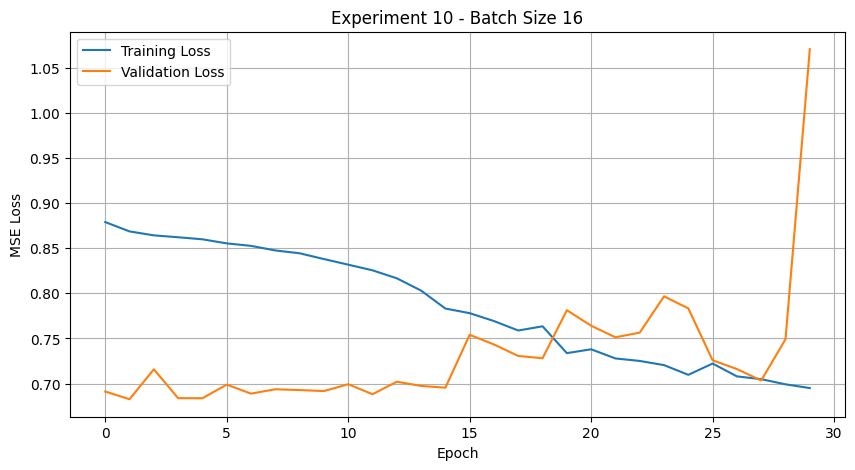

In [265]:
# EXPERIMENT 10 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp10_train_losses,
    label="Training Loss"
)

plt.plot(
    exp10_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 10 - Batch Size 16")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()


In [266]:
# EXPERIMENT 11 - SETUP BATCH SIZE 32

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp11_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 32
exp11_train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

# Define loss function
exp11_criterion = nn.MSELoss()

# Define Adam optimizer
exp11_optimizer = optim.Adam(
    exp11_model.parameters(),
    lr=0.001
)

# Initialize loss lists
exp11_train_losses = []
exp11_val_losses = []

# Number of epochs
exp11_epochs = 30

print("Experiment 11 setup completed!")

Experiment 11 setup completed!


In [267]:
# EXPERIMENT 11 - TRAIN MODEL

for epoch in range(exp11_epochs):

    exp11_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp11_train_loader:

        # Forward pass
        predictions = exp11_model(X_batch)

        # Calculate loss
        loss = exp11_criterion(predictions, y_batch)

        # Backpropagation
        exp11_optimizer.zero_grad()
        loss.backward()
        exp11_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp11_model.eval()

    with torch.no_grad():

        val_predictions = exp11_model(X_val_tensor)

        val_loss = exp11_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp11_train_losses.append(train_loss)
    exp11_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp11_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 11 completed!")

Epoch [1/30], Train Loss: 0.8787, Val Loss: 0.6882
Epoch [2/30], Train Loss: 0.8669, Val Loss: 0.6831
Epoch [3/30], Train Loss: 0.8622, Val Loss: 0.7113
Epoch [4/30], Train Loss: 0.8592, Val Loss: 0.6836
Epoch [5/30], Train Loss: 0.8554, Val Loss: 0.6854
Epoch [6/30], Train Loss: 0.8503, Val Loss: 0.6906
Epoch [7/30], Train Loss: 0.8450, Val Loss: 0.6951
Epoch [8/30], Train Loss: 0.8386, Val Loss: 0.6949
Epoch [9/30], Train Loss: 0.8325, Val Loss: 0.6944
Epoch [10/30], Train Loss: 0.8222, Val Loss: 0.6937
Epoch [11/30], Train Loss: 0.8097, Val Loss: 0.6961
Epoch [12/30], Train Loss: 0.7997, Val Loss: 0.6989
Epoch [13/30], Train Loss: 0.7747, Val Loss: 0.7151
Epoch [14/30], Train Loss: 0.7613, Val Loss: 0.6963
Epoch [15/30], Train Loss: 0.7471, Val Loss: 0.6927
Epoch [16/30], Train Loss: 0.7329, Val Loss: 0.7674
Epoch [17/30], Train Loss: 0.7178, Val Loss: 0.7120
Epoch [18/30], Train Loss: 0.7076, Val Loss: 0.7591
Epoch [19/30], Train Loss: 0.6902, Val Loss: 0.7227
Epoch [20/30], Train 

In [268]:
# EXPERIMENT 11 - EVALUATE MODEL

exp11_model.eval()

with torch.no_grad():

    exp11_val_scaled = exp11_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp11_val_predictions = target_scaler.inverse_transform(
        exp11_val_scaled
    )

    # Calculate validation MSE
    exp11_val_mse = mean_squared_error(
        y_val,
        exp11_val_predictions
    )

print("Experiment 11 Validation MSE:", exp11_val_mse)

Experiment 11 Validation MSE: 5657525248.0


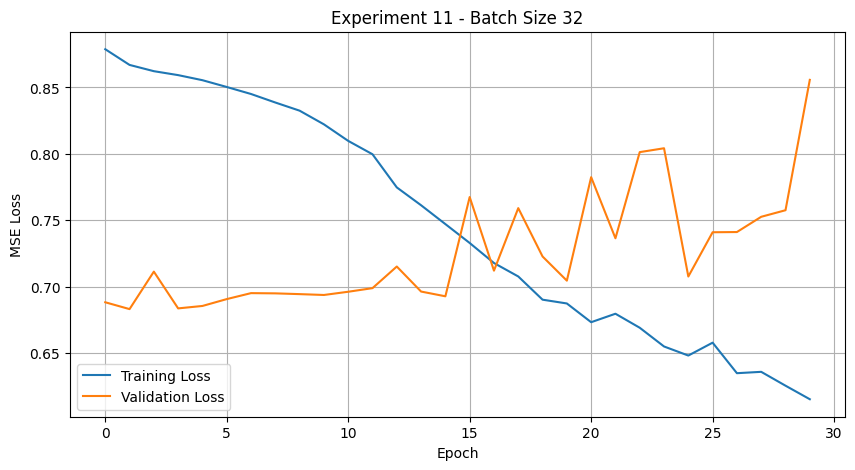

In [269]:
# EXPERIMENT 11 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp11_train_losses,
    label="Training Loss"
)

plt.plot(
    exp11_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 11 - Batch Size 32")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [270]:
# EXPERIMENT 12 - SETUP BATCH SIZE 64

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp12_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 64
exp12_train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# Define loss function
exp12_criterion = nn.MSELoss()

# Define Adam optimizer
exp12_optimizer = optim.Adam(
    exp12_model.parameters(),
    lr=0.001
)

# Initialize loss lists
exp12_train_losses = []
exp12_val_losses = []

# Number of epochs
exp12_epochs = 30

print("Experiment 12 setup completed!")

Experiment 12 setup completed!


In [271]:
# EXPERIMENT 12 - TRAIN MODEL

for epoch in range(exp12_epochs):

    exp12_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp12_train_loader:

        # Forward pass
        predictions = exp12_model(X_batch)

        # Calculate loss
        loss = exp12_criterion(predictions, y_batch)

        # Backpropagation
        exp12_optimizer.zero_grad()
        loss.backward()
        exp12_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp12_model.eval()

    with torch.no_grad():

        val_predictions = exp12_model(X_val_tensor)

        val_loss = exp12_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp12_train_losses.append(train_loss)
    exp12_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp12_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 12 completed!")

Epoch [1/30], Train Loss: 0.8780, Val Loss: 0.6874
Epoch [2/30], Train Loss: 0.8663, Val Loss: 0.6840
Epoch [3/30], Train Loss: 0.8609, Val Loss: 0.7044
Epoch [4/30], Train Loss: 0.8576, Val Loss: 0.6849
Epoch [5/30], Train Loss: 0.8515, Val Loss: 0.6872
Epoch [6/30], Train Loss: 0.8463, Val Loss: 0.6887
Epoch [7/30], Train Loss: 0.8387, Val Loss: 0.6991
Epoch [8/30], Train Loss: 0.8327, Val Loss: 0.6919
Epoch [9/30], Train Loss: 0.8214, Val Loss: 0.7014
Epoch [10/30], Train Loss: 0.8068, Val Loss: 0.6900
Epoch [11/30], Train Loss: 0.7871, Val Loss: 0.7113
Epoch [12/30], Train Loss: 0.7613, Val Loss: 0.7233
Epoch [13/30], Train Loss: 0.7394, Val Loss: 0.7099
Epoch [14/30], Train Loss: 0.7062, Val Loss: 0.6968
Epoch [15/30], Train Loss: 0.7042, Val Loss: 0.7136
Epoch [16/30], Train Loss: 0.6991, Val Loss: 0.7837
Epoch [17/30], Train Loss: 0.6847, Val Loss: 0.7262
Epoch [18/30], Train Loss: 0.6692, Val Loss: 0.7785
Epoch [19/30], Train Loss: 0.6614, Val Loss: 0.7001
Epoch [20/30], Train 

In [272]:
# EXPERIMENT 12 - EVALUATE MODEL

exp12_model.eval()

with torch.no_grad():

    exp12_val_scaled = exp12_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp12_val_predictions = target_scaler.inverse_transform(
        exp12_val_scaled
    )

    # Calculate validation MSE
    exp12_val_mse = mean_squared_error(
        y_val,
        exp12_val_predictions
    )

print("Experiment 12 Validation MSE:", exp12_val_mse)

Experiment 12 Validation MSE: 5612618240.0


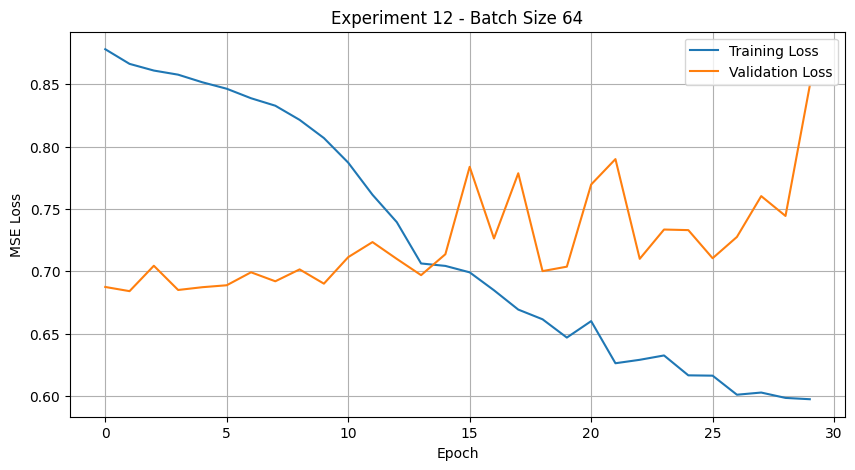

In [273]:
# EXPERIMENT 12 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp12_train_losses,
    label="Training Loss"
)

plt.plot(
    exp12_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 12 - Batch Size 64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [274]:
# EXPERIMENT 13 - SETUP BATCH SIZE 128

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp13_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 128
exp13_train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

# Define loss function
exp13_criterion = nn.MSELoss()

# Define Adam optimizer
exp13_optimizer = optim.Adam(
    exp13_model.parameters(),
    lr=0.001
)

# Initialize loss lists
exp13_train_losses = []
exp13_val_losses = []

# Number of epochs
exp13_epochs = 30

print("Experiment 13 setup completed!")

Experiment 13 setup completed!


In [275]:
# EXPERIMENT 13 - TRAIN MODEL

for epoch in range(exp13_epochs):

    exp13_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp13_train_loader:

        # Forward pass
        predictions = exp13_model(X_batch)

        # Calculate loss
        loss = exp13_criterion(predictions, y_batch)

        # Backpropagation
        exp13_optimizer.zero_grad()
        loss.backward()
        exp13_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp13_model.eval()

    with torch.no_grad():

        val_predictions = exp13_model(X_val_tensor)

        val_loss = exp13_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp13_train_losses.append(train_loss)
    exp13_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp13_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 13 completed!")

Epoch [1/30], Train Loss: 0.8790, Val Loss: 0.6870
Epoch [2/30], Train Loss: 0.8663, Val Loss: 0.6853
Epoch [3/30], Train Loss: 0.8616, Val Loss: 0.6929
Epoch [4/30], Train Loss: 0.8588, Val Loss: 0.6853
Epoch [5/30], Train Loss: 0.8526, Val Loss: 0.6848
Epoch [6/30], Train Loss: 0.8484, Val Loss: 0.6876
Epoch [7/30], Train Loss: 0.8411, Val Loss: 0.6997
Epoch [8/30], Train Loss: 0.8353, Val Loss: 0.6947
Epoch [9/30], Train Loss: 0.8248, Val Loss: 0.6973
Epoch [10/30], Train Loss: 0.8110, Val Loss: 0.6893
Epoch [11/30], Train Loss: 0.7895, Val Loss: 0.7478
Epoch [12/30], Train Loss: 0.7616, Val Loss: 0.6963
Epoch [13/30], Train Loss: 0.7353, Val Loss: 0.7090
Epoch [14/30], Train Loss: 0.7143, Val Loss: 0.7019
Epoch [15/30], Train Loss: 0.6983, Val Loss: 0.7318
Epoch [16/30], Train Loss: 0.6847, Val Loss: 0.8228
Epoch [17/30], Train Loss: 0.6731, Val Loss: 0.7609
Epoch [18/30], Train Loss: 0.6705, Val Loss: 0.7782
Epoch [19/30], Train Loss: 0.6586, Val Loss: 0.7659
Epoch [20/30], Train 

In [276]:
# EXPERIMENT 13 - EVALUATE MODEL

exp13_model.eval()

with torch.no_grad():

    exp13_val_scaled = exp13_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp13_val_predictions = target_scaler.inverse_transform(
        exp13_val_scaled
    )

    # Calculate validation MSE
    exp13_val_mse = mean_squared_error(
        y_val,
        exp13_val_predictions
    )

print("Experiment 13 Validation MSE:", exp13_val_mse)

Experiment 13 Validation MSE: 5913121280.0


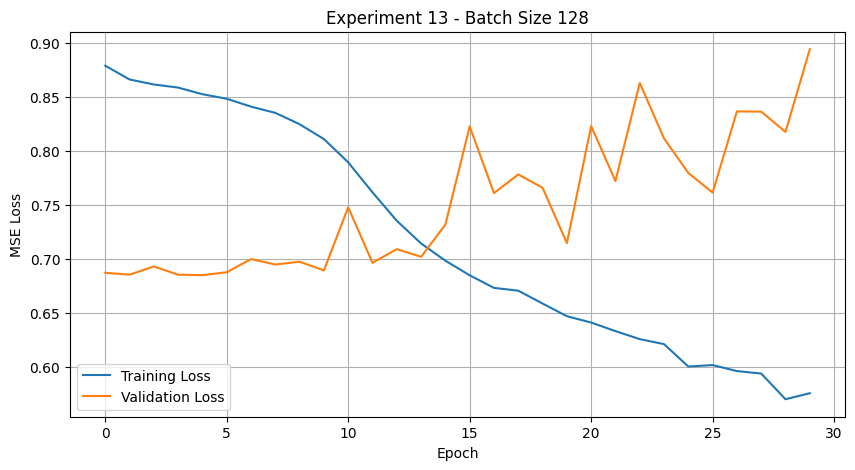

In [277]:
# EXPERIMENT 13 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp13_train_losses,
    label="Training Loss"
)

plt.plot(
    exp13_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 13 - Batch Size 128")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [278]:
# EXPERIMENT 14 - SETUP BATCH SIZE 256

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp14_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 256
exp14_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
exp14_criterion = nn.MSELoss()

# Define Adam optimizer
exp14_optimizer = optim.Adam(
    exp14_model.parameters(),
    lr=0.001
)

# Initialize loss lists
exp14_train_losses = []
exp14_val_losses = []

# Number of epochs
exp14_epochs = 30

print("Experiment 14 setup completed!")

Experiment 14 setup completed!


In [279]:
# EXPERIMENT 14 - TRAIN MODEL

for epoch in range(exp14_epochs):

    exp14_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp14_train_loader:

        # Forward pass
        predictions = exp14_model(X_batch)

        # Calculate loss
        loss = exp14_criterion(predictions, y_batch)

        # Backpropagation
        exp14_optimizer.zero_grad()
        loss.backward()
        exp14_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp14_model.eval()

    with torch.no_grad():

        val_predictions = exp14_model(X_val_tensor)

        val_loss = exp14_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp14_train_losses.append(train_loss)
    exp14_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp14_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 14 completed!")

Epoch [1/30], Train Loss: 0.8814, Val Loss: 0.6865
Epoch [2/30], Train Loss: 0.8663, Val Loss: 0.6861
Epoch [3/30], Train Loss: 0.8611, Val Loss: 0.6915
Epoch [4/30], Train Loss: 0.8583, Val Loss: 0.6848
Epoch [5/30], Train Loss: 0.8524, Val Loss: 0.6861
Epoch [6/30], Train Loss: 0.8492, Val Loss: 0.6859
Epoch [7/30], Train Loss: 0.8409, Val Loss: 0.7030
Epoch [8/30], Train Loss: 0.8361, Val Loss: 0.6960
Epoch [9/30], Train Loss: 0.8235, Val Loss: 0.7059
Epoch [10/30], Train Loss: 0.8151, Val Loss: 0.6914
Epoch [11/30], Train Loss: 0.7910, Val Loss: 0.7392
Epoch [12/30], Train Loss: 0.7782, Val Loss: 0.6987
Epoch [13/30], Train Loss: 0.7557, Val Loss: 0.6932
Epoch [14/30], Train Loss: 0.7218, Val Loss: 0.6952
Epoch [15/30], Train Loss: 0.7060, Val Loss: 0.7011
Epoch [16/30], Train Loss: 0.6988, Val Loss: 0.8079
Epoch [17/30], Train Loss: 0.6898, Val Loss: 0.7141
Epoch [18/30], Train Loss: 0.6819, Val Loss: 0.7539
Epoch [19/30], Train Loss: 0.6804, Val Loss: 0.7275
Epoch [20/30], Train 

In [280]:
# EXPERIMENT 14 - EVALUATE MODEL

exp14_model.eval()

with torch.no_grad():

    exp14_val_scaled = exp14_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp14_val_predictions = target_scaler.inverse_transform(
        exp14_val_scaled
    )

    # Calculate validation MSE
    exp14_val_mse = mean_squared_error(
        y_val,
        exp14_val_predictions
    )

print("Experiment 14 Validation MSE:", exp14_val_mse)

Experiment 14 Validation MSE: 5419734528.0


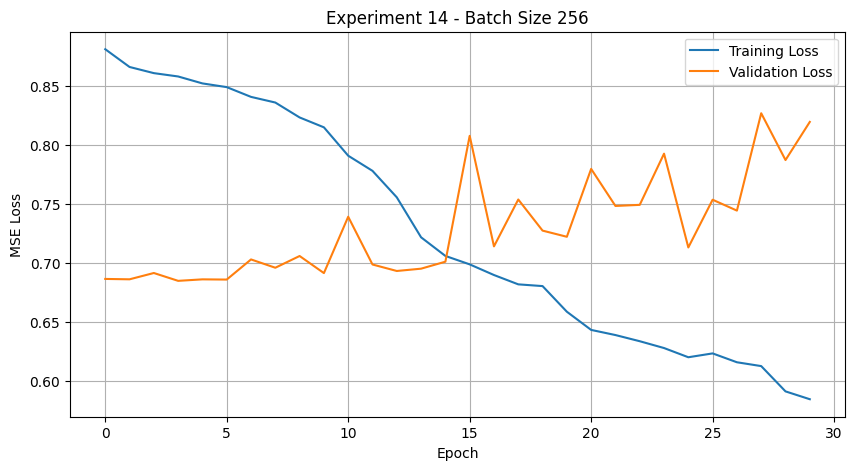

In [281]:
# EXPERIMENT 14 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp14_train_losses,
    label="Training Loss"
)

plt.plot(
    exp14_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 14 - Batch Size 256")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [282]:
# EXPERIMENT 15 - SETUP BATCH SIZE 512

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp15_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 512
exp15_train_loader = DataLoader(
    train_dataset,
    batch_size=512,
    shuffle=True
)

# Define loss function
exp15_criterion = nn.MSELoss()

# Define Adam optimizer
exp15_optimizer = optim.Adam(
    exp15_model.parameters(),
    lr=0.001
)

# Initialize loss lists
exp15_train_losses = []
exp15_val_losses = []

# Number of epochs
exp15_epochs = 30

print("Experiment 15 setup completed!")

Experiment 15 setup completed!


In [283]:
# EXPERIMENT 15 - TRAIN MODEL

for epoch in range(exp15_epochs):

    exp15_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp15_train_loader:

        # Forward pass
        predictions = exp15_model(X_batch)

        # Calculate loss
        loss = exp15_criterion(predictions, y_batch)

        # Backpropagation
        exp15_optimizer.zero_grad()
        loss.backward()
        exp15_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp15_model.eval()

    with torch.no_grad():

        val_predictions = exp15_model(X_val_tensor)

        val_loss = exp15_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp15_train_losses.append(train_loss)
    exp15_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp15_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 15 completed!")

Epoch [1/30], Train Loss: 0.8858, Val Loss: 0.6864
Epoch [2/30], Train Loss: 0.8663, Val Loss: 0.6840
Epoch [3/30], Train Loss: 0.8609, Val Loss: 0.6937
Epoch [4/30], Train Loss: 0.8584, Val Loss: 0.6859
Epoch [5/30], Train Loss: 0.8535, Val Loss: 0.6858
Epoch [6/30], Train Loss: 0.8503, Val Loss: 0.6866
Epoch [7/30], Train Loss: 0.8445, Val Loss: 0.6963
Epoch [8/30], Train Loss: 0.8406, Val Loss: 0.6974
Epoch [9/30], Train Loss: 0.8305, Val Loss: 0.7103
Epoch [10/30], Train Loss: 0.8241, Val Loss: 0.6959
Epoch [11/30], Train Loss: 0.8085, Val Loss: 0.7451
Epoch [12/30], Train Loss: 0.7989, Val Loss: 0.7050
Epoch [13/30], Train Loss: 0.7748, Val Loss: 0.6905
Epoch [14/30], Train Loss: 0.7469, Val Loss: 0.6947
Epoch [15/30], Train Loss: 0.7276, Val Loss: 0.6922
Epoch [16/30], Train Loss: 0.7159, Val Loss: 0.7756
Epoch [17/30], Train Loss: 0.6924, Val Loss: 0.7635
Epoch [18/30], Train Loss: 0.6813, Val Loss: 0.8256
Epoch [19/30], Train Loss: 0.6721, Val Loss: 0.7642
Epoch [20/30], Train 

In [284]:
# EXPERIMENT 15 - EVALUATE MODEL

exp15_model.eval()

with torch.no_grad():

    exp15_val_scaled = exp15_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp15_val_predictions = target_scaler.inverse_transform(
        exp15_val_scaled
    )

    # Calculate validation MSE
    exp15_val_mse = mean_squared_error(
        y_val,
        exp15_val_predictions
    )

print("Experiment 15 Validation MSE:", exp15_val_mse)

Experiment 15 Validation MSE: 5540334080.0


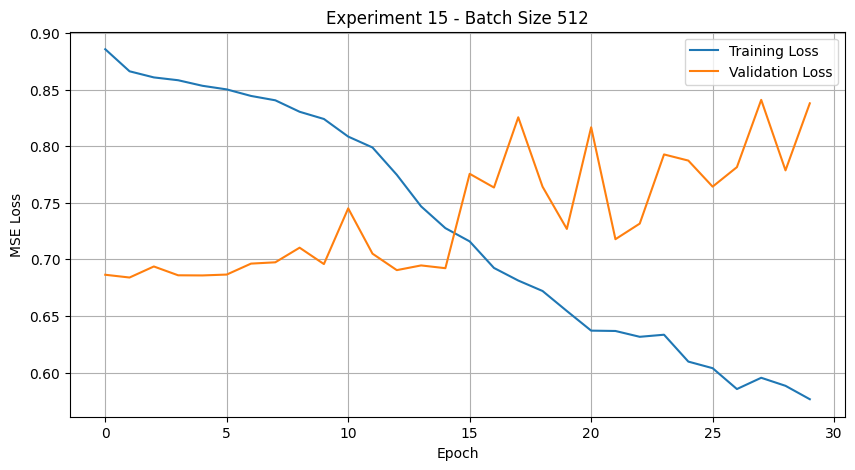

In [285]:
# EXPERIMENT 15 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp15_train_losses,
    label="Training Loss"
)

plt.plot(
    exp15_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 15 - Batch Size 512")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [286]:
# EXPERIMENT 16 - SETUP BATCH SIZE 8

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp16_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 8
exp16_train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

# Define loss function
exp16_criterion = nn.MSELoss()

# Define Adam optimizer
exp16_optimizer = optim.Adam(
    exp16_model.parameters(),
    lr=0.001
)

# Initialize loss lists
exp16_train_losses = []
exp16_val_losses = []

# Number of epochs
exp16_epochs = 30

print("Experiment 16 setup completed!")

Experiment 16 setup completed!


In [287]:
# EXPERIMENT 16 - TRAIN MODEL

for epoch in range(exp16_epochs):

    exp16_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp16_train_loader:

        predictions = exp16_model(X_batch)

        loss = exp16_criterion(predictions, y_batch)

        exp16_optimizer.zero_grad()
        loss.backward()
        exp16_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    train_loss = total_train_loss / len(train_dataset)

    # Validate model
    exp16_model.eval()

    with torch.no_grad():

        val_predictions = exp16_model(X_val_tensor)

        val_loss = exp16_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    exp16_train_losses.append(train_loss)
    exp16_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 16 completed!")

Epoch [1/30], Train Loss: 0.8793, Val Loss: 0.6918
Epoch [2/30], Train Loss: 0.8701, Val Loss: 0.6840
Epoch [3/30], Train Loss: 0.8663, Val Loss: 0.7024
Epoch [4/30], Train Loss: 0.8649, Val Loss: 0.6838
Epoch [5/30], Train Loss: 0.8630, Val Loss: 0.6846
Epoch [6/30], Train Loss: 0.8602, Val Loss: 0.7134
Epoch [7/30], Train Loss: 0.8601, Val Loss: 0.6858
Epoch [8/30], Train Loss: 0.8594, Val Loss: 0.6860
Epoch [9/30], Train Loss: 0.8583, Val Loss: 0.6866
Epoch [10/30], Train Loss: 0.8572, Val Loss: 0.6889
Epoch [11/30], Train Loss: 0.8551, Val Loss: 0.6877
Epoch [12/30], Train Loss: 0.8536, Val Loss: 0.6873
Epoch [13/30], Train Loss: 0.8531, Val Loss: 0.6871
Epoch [14/30], Train Loss: 0.8516, Val Loss: 0.6901
Epoch [15/30], Train Loss: 0.8503, Val Loss: 0.6883
Epoch [16/30], Train Loss: 0.8476, Val Loss: 0.7011
Epoch [17/30], Train Loss: 0.8452, Val Loss: 0.6929
Epoch [18/30], Train Loss: 0.8435, Val Loss: 0.6962
Epoch [19/30], Train Loss: 0.8420, Val Loss: 0.6993
Epoch [20/30], Train 

In [288]:
# EXPERIMENT 16 - EVALUATE MODEL

exp16_model.eval()

with torch.no_grad():

    exp16_val_scaled = exp16_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp16_val_predictions = target_scaler.inverse_transform(
        exp16_val_scaled
    )

    # Calculate validation MSE
    exp16_val_mse = mean_squared_error(
        y_val,
        exp16_val_predictions
    )

print("Experiment 16 Validation MSE:", exp16_val_mse)

Experiment 16 Validation MSE: 5037245440.0


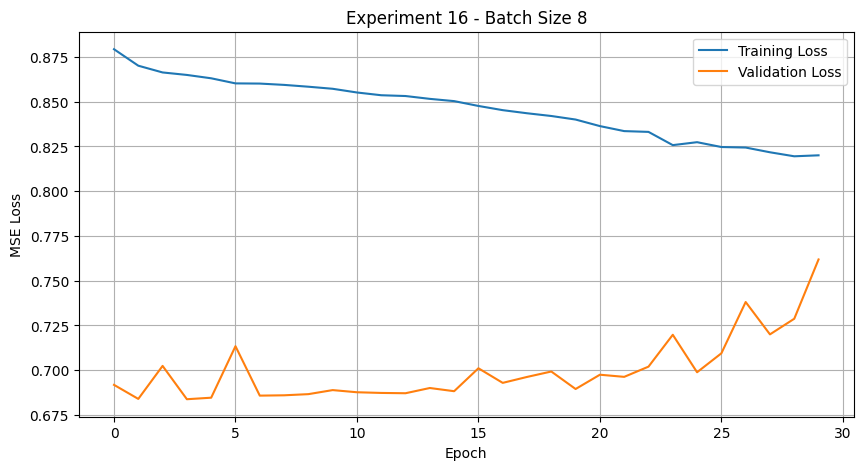

In [289]:
# EXPERIMENT 16 - PLOT TRAINING AND VALIDATION LOSS

plt.figure(figsize=(10, 5))

plt.plot(
    exp16_train_losses,
    label="Training Loss"
)

plt.plot(
    exp16_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 16 - Batch Size 8")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [290]:
# EXPERIMENT 17: INCREASING NETWORK WIDTH
# Learning Rate = 0.001
# Neurons = 128
# Optimizer = Adam

# 1. Create a fresh DNN model

class Experiment17Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp17_model = Experiment17Model(input_size=315)

print(exp17_model)

Experiment17Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [291]:
# 3. Create DataLoader

exp17_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# 4. Define loss function

exp17_criterion = nn.MSELoss()

# 5. Define optimizer (Adam)

exp17_optimizer = optim.Adam(
    exp17_model.parameters(),
    lr=0.001
)

# 6. Set number of epochs

exp17_epochs = 30

# 7. Store training and validation losses

exp17_train_losses = []
exp17_val_losses = []

print("Experiment 17 training setup completed!")

Experiment 17 training setup completed!


In [292]:
# EXPERIMENT 17 - START TRAINING

import time

exp17_start_time = time.time()

for epoch in range(exp17_epochs):

    exp17_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp17_train_loader:

        predictions = exp17_model(X_batch)

        loss = exp17_criterion(predictions, y_batch)

        exp17_optimizer.zero_grad()
        loss.backward()
        exp17_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp17_model.eval()

    with torch.no_grad():

        val_predictions = exp17_model(X_val_tensor)

        val_loss = exp17_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    exp17_train_losses.append(train_loss)
    exp17_val_losses.append(val_loss)

    # Display results
    print(
        f"Epoch [{epoch+1}/{exp17_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time
exp17_training_time = time.time() - exp17_start_time
print("________________________")
print("Experiment 17 completed!")
print("Final training loss:", exp17_train_losses[-1])
print("Final validation loss:", exp17_val_losses[-1])
print("Training time:", round(exp17_training_time, 2), "seconds")

Epoch [1/30], Train Loss: 0.8790, Val Loss: 0.6838
Epoch [2/30], Train Loss: 0.8661, Val Loss: 0.6853
Epoch [3/30], Train Loss: 0.8617, Val Loss: 0.6891
Epoch [4/30], Train Loss: 0.8553, Val Loss: 0.6897
Epoch [5/30], Train Loss: 0.8492, Val Loss: 0.6871
Epoch [6/30], Train Loss: 0.8418, Val Loss: 0.6899
Epoch [7/30], Train Loss: 0.8312, Val Loss: 0.6939
Epoch [8/30], Train Loss: 0.8169, Val Loss: 0.7072
Epoch [9/30], Train Loss: 0.7970, Val Loss: 0.7174
Epoch [10/30], Train Loss: 0.7556, Val Loss: 0.7069
Epoch [11/30], Train Loss: 0.7448, Val Loss: 0.7107
Epoch [12/30], Train Loss: 0.7204, Val Loss: 0.7446
Epoch [13/30], Train Loss: 0.6927, Val Loss: 0.7182
Epoch [14/30], Train Loss: 0.6744, Val Loss: 0.7768
Epoch [15/30], Train Loss: 0.6634, Val Loss: 0.7778
Epoch [16/30], Train Loss: 0.6648, Val Loss: 0.7322
Epoch [17/30], Train Loss: 0.6449, Val Loss: 0.7489
Epoch [18/30], Train Loss: 0.6356, Val Loss: 0.7800
Epoch [19/30], Train Loss: 0.6175, Val Loss: 0.8435
Epoch [20/30], Train 

In [293]:
# EXPERIMENT 17 - EVALUATE MODEL

exp17_model.eval()

with torch.no_grad():

    exp17_val_scaled = exp17_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp17_val_predictions = target_scaler.inverse_transform(
        exp17_val_scaled
    )

    # Calculate validation MSE

    exp17_val_mse = mean_squared_error(
        y_val,
        exp17_val_predictions
    )

print("Experiment 17 Validation MSE:", exp17_val_mse)

Experiment 17 Validation MSE: 5290758656.0


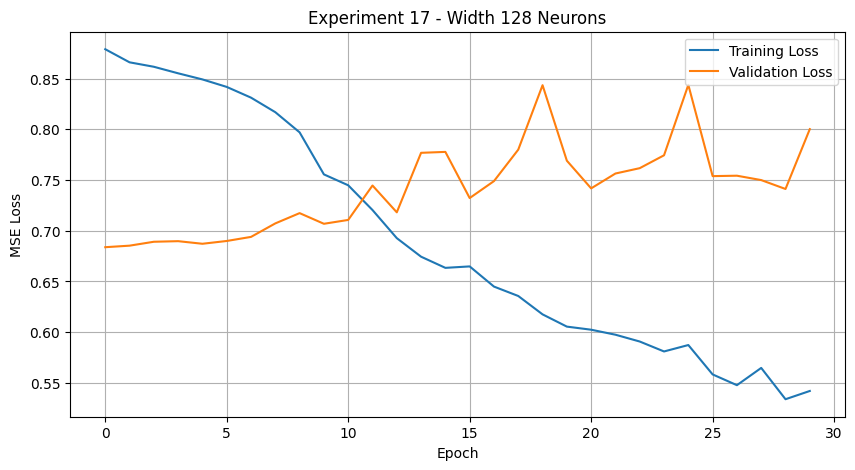

In [294]:
# EXPERIMENT 17- PLOT TRAINING AND VALIDATION LOSS

plt.figure(figsize=(10, 5))

plt.plot(exp17_train_losses, label="Training Loss")
plt.plot(exp17_val_losses, label="Validation Loss")

plt.title("Experiment 17 - Width 128 Neurons")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [295]:
# EXPERIMENT 18 - DECREASING NETWORK WIDTH
# Neurons = 32
# Learning Rate = 0.001

# 1. Create a fresh DNN model

class Experiment18Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp18_model = Experiment18Model(input_size=315)

print(exp18_model)

Experiment18Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [296]:
# 3. Create DataLoader

exp18_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# 4. Define loss function

exp18_criterion = nn.MSELoss()

# 5. Define optimizer

exp18_optimizer = optim.Adam(
    exp18_model.parameters(),
    lr=0.001
)

# 6. Set number of epochs

exp18_epochs = 30

print("Experiment 18 training setup completed!")

# 7. Store training and validation losses

exp18_train_losses = []
exp18_val_losses = []

Experiment 18 training setup completed!


In [297]:
# 8. Start training

import time

exp18_start_time = time.time()

for epoch in range(exp18_epochs):

    exp18_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp18_train_loader:

        predictions = exp18_model(X_batch)

        loss = exp18_criterion(predictions, y_batch)

        exp18_optimizer.zero_grad()
        loss.backward()
        exp18_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # 9. Validation

    exp18_model.eval()

    with torch.no_grad():

        val_predictions = exp18_model(X_val_tensor)

        val_loss = exp18_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # 10. Save losses

    exp18_train_losses.append(train_loss)
    exp18_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp18_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# 11. Calculate training time

exp18_training_time = time.time() - exp18_start_time

print(f"Training time: {exp18_training_time:.2f} seconds")

# 12. Display final results

print("Experiment 18 completed!")

print("Final training MSE:", exp18_train_losses[-1])
print("Final validation MSE:", exp18_val_losses[-1])

print(
    "Training time:",
    round(exp18_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.8854, Val Loss: 0.6858
Epoch [2/30], Train Loss: 0.8666, Val Loss: 0.6847
Epoch [3/30], Train Loss: 0.8630, Val Loss: 0.6835
Epoch [4/30], Train Loss: 0.8611, Val Loss: 0.6822
Epoch [5/30], Train Loss: 0.8583, Val Loss: 0.6895
Epoch [6/30], Train Loss: 0.8559, Val Loss: 0.6860
Epoch [7/30], Train Loss: 0.8542, Val Loss: 0.6880
Epoch [8/30], Train Loss: 0.8509, Val Loss: 0.6926
Epoch [9/30], Train Loss: 0.8483, Val Loss: 0.6882
Epoch [10/30], Train Loss: 0.8438, Val Loss: 0.6906
Epoch [11/30], Train Loss: 0.8401, Val Loss: 0.6897
Epoch [12/30], Train Loss: 0.8366, Val Loss: 0.6935
Epoch [13/30], Train Loss: 0.8309, Val Loss: 0.6962
Epoch [14/30], Train Loss: 0.8231, Val Loss: 0.6985
Epoch [15/30], Train Loss: 0.8153, Val Loss: 0.7177
Epoch [16/30], Train Loss: 0.8071, Val Loss: 0.7255
Epoch [17/30], Train Loss: 0.7944, Val Loss: 0.7235
Epoch [18/30], Train Loss: 0.7762, Val Loss: 0.7178
Epoch [19/30], Train Loss: 0.7659, Val Loss: 0.7204
Epoch [20/30], Train 

In [298]:
# EXPERIMENT 18 - EVALUATE MODEL

exp18_model.eval()

with torch.no_grad():

    exp18_val_scaled = exp18_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp18_val_predictions = target_scaler.inverse_transform(
        exp18_val_scaled
    )

    # Calculate validation MSE

    exp18_val_mse = mean_squared_error(
        y_val,
        exp18_val_predictions
    )

print("Experiment 18 Validation MSE:", exp18_val_mse)

Experiment 18 Validation MSE: 4792413184.0


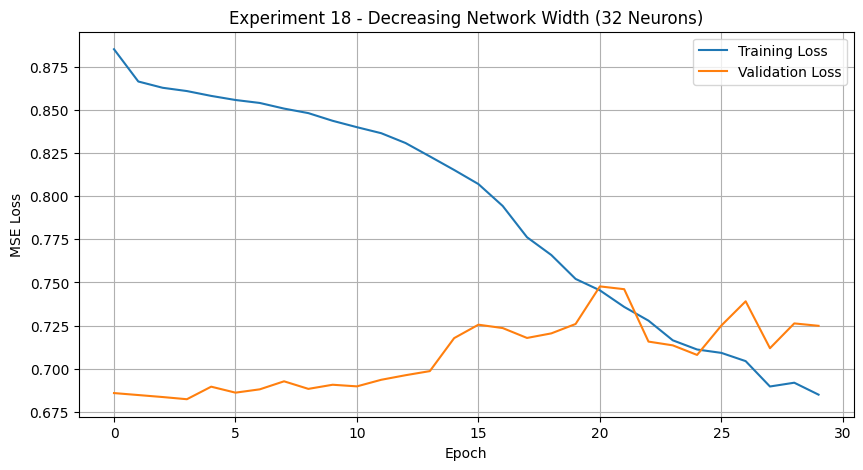

In [299]:
# EXPERIMENT 18 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(exp18_train_losses, label="Training Loss")
plt.plot(exp18_val_losses, label="Validation Loss")

plt.title("Experiment 18 - Decreasing Network Width (32 Neurons)")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [300]:
# EXPERIMENT 19 - NETWORK WIDTH = 16
# Learning Rate = 0.001
# Optimizer = Adam

# 1. Create a fresh DNN model

class Experiment19Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp19_model = Experiment19Model(input_size=315)

print(exp19_model)

Experiment19Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [301]:
# 3. Create DataLoader

exp19_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# 4. Define loss function

exp19_criterion = nn.MSELoss()

# 5. Define optimizer

exp19_optimizer = optim.Adam(
    exp19_model.parameters(),
    lr=0.001
)

# 6. Set number of epochs

exp19_epochs = 30

# 7. Store training and validation losses

exp19_train_losses = []
exp19_val_losses = []

print("Experiment 19 training setup completed!")

Experiment 19 training setup completed!


In [302]:
# 8. Start training

import time

exp19_start_time = time.time()

for epoch in range(exp19_epochs):

    exp19_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp19_train_loader:

        predictions = exp19_model(X_batch)

        loss = exp19_criterion(predictions, y_batch)

        exp19_optimizer.zero_grad()
        loss.backward()
        exp19_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # 9. Validation

    exp19_model.eval()

    with torch.no_grad():

        val_predictions = exp19_model(X_val_tensor)

        val_loss = exp19_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # 10. Save losses

    exp19_train_losses.append(train_loss)
    exp19_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp19_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# 11. Calculate training time

exp19_training_time = time.time() - exp19_start_time

print(f"Training time: {exp19_training_time:.2f} seconds")

# 12. Display final results

print("Experiment 19 completed!")

print("Final training MSE:", exp19_train_losses[-1])
print("Final validation MSE:", exp19_val_losses[-1])

print(
    "Training time:",
    round(exp19_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.8915, Val Loss: 0.6866
Epoch [2/30], Train Loss: 0.8679, Val Loss: 0.6842
Epoch [3/30], Train Loss: 0.8651, Val Loss: 0.6943
Epoch [4/30], Train Loss: 0.8631, Val Loss: 0.6841
Epoch [5/30], Train Loss: 0.8605, Val Loss: 0.6825
Epoch [6/30], Train Loss: 0.8595, Val Loss: 0.6847
Epoch [7/30], Train Loss: 0.8580, Val Loss: 0.6828
Epoch [8/30], Train Loss: 0.8566, Val Loss: 0.6851
Epoch [9/30], Train Loss: 0.8553, Val Loss: 0.6844
Epoch [10/30], Train Loss: 0.8530, Val Loss: 0.6862
Epoch [11/30], Train Loss: 0.8511, Val Loss: 0.6833
Epoch [12/30], Train Loss: 0.8498, Val Loss: 0.6837
Epoch [13/30], Train Loss: 0.8470, Val Loss: 0.6857
Epoch [14/30], Train Loss: 0.8442, Val Loss: 0.6851
Epoch [15/30], Train Loss: 0.8417, Val Loss: 0.6905
Epoch [16/30], Train Loss: 0.8396, Val Loss: 0.6869
Epoch [17/30], Train Loss: 0.8356, Val Loss: 0.6869
Epoch [18/30], Train Loss: 0.8330, Val Loss: 0.6972
Epoch [19/30], Train Loss: 0.8262, Val Loss: 0.7097
Epoch [20/30], Train 

In [303]:
# EXPERIMENT 19 - EVALUATE MODEL

exp19_model.eval()

with torch.no_grad():

    exp19_val_scaled = exp19_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp19_val_predictions = target_scaler.inverse_transform(
        exp19_val_scaled
    )

    # Calculate validation MSE

    exp19_val_mse = mean_squared_error(
        y_val,
        exp19_val_predictions
    )

print("Experiment 19 Validation MSE:", exp19_val_mse)

Experiment 19 Validation MSE: 4907494400.0


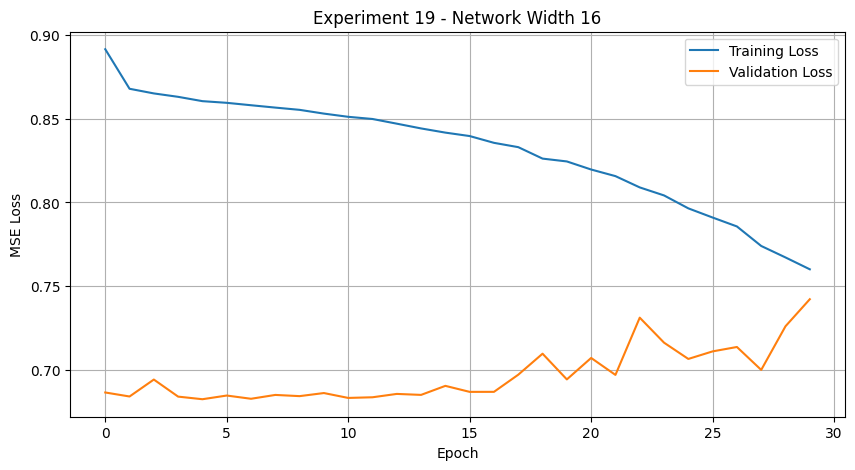

In [304]:
# EXPERIMENT 19 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(exp19_train_losses, label="Training Loss")
plt.plot(exp19_val_losses, label="Validation Loss")

plt.title("Experiment 19 - Network Width 16")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [305]:
# EXPERIMENT 20 - NETWORK WIDTH 64

# 1. Create a fresh DNN model

class Experiment20Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp20_model = Experiment20Model(input_size=315)

print(exp20_model)

Experiment20Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [306]:
# 3. Create DataLoader

exp20_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# 4. Define loss function

exp20_criterion = nn.MSELoss()

# 5. Define optimizer

exp20_optimizer = optim.Adam(
    exp20_model.parameters(),
    lr=0.001
)

# 6. Set number of epochs

exp20_epochs = 30

# 7. Store training and validation losses

exp20_train_losses = []
exp20_val_losses = []

print("Experiment 20 training setup completed!")

Experiment 20 training setup completed!


In [307]:
# 8. Start training

import time

exp20_start_time = time.time()

for epoch in range(exp20_epochs):

    exp20_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp20_train_loader:

        predictions = exp20_model(X_batch)

        loss = exp20_criterion(predictions, y_batch)

        exp20_optimizer.zero_grad()
        loss.backward()
        exp20_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # 9. Validation

    exp20_model.eval()

    with torch.no_grad():

        val_predictions = exp20_model(X_val_tensor)

        val_loss = exp20_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # 10. Save losses

    exp20_train_losses.append(train_loss)
    exp20_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp20_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# 11. Calculate training time

exp20_training_time = time.time() - exp20_start_time

print(f"Training time: {exp20_training_time:.2f} seconds")

# 12. Display final results

print("Experiment 20 completed!")

print("Final training MSE:", exp20_train_losses[-1])
print("Final validation MSE:", exp20_val_losses[-1])

print(
    "Training time:",
    round(exp20_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.8822, Val Loss: 0.6848
Epoch [2/30], Train Loss: 0.8658, Val Loss: 0.6811
Epoch [3/30], Train Loss: 0.8618, Val Loss: 0.6860
Epoch [4/30], Train Loss: 0.8583, Val Loss: 0.6865
Epoch [5/30], Train Loss: 0.8547, Val Loss: 0.6928
Epoch [6/30], Train Loss: 0.8495, Val Loss: 0.6962
Epoch [7/30], Train Loss: 0.8442, Val Loss: 0.6890
Epoch [8/30], Train Loss: 0.8369, Val Loss: 0.6937
Epoch [9/30], Train Loss: 0.8259, Val Loss: 0.6954
Epoch [10/30], Train Loss: 0.8123, Val Loss: 0.7256
Epoch [11/30], Train Loss: 0.8025, Val Loss: 0.7273
Epoch [12/30], Train Loss: 0.7826, Val Loss: 0.7177
Epoch [13/30], Train Loss: 0.7635, Val Loss: 0.7025
Epoch [14/30], Train Loss: 0.7434, Val Loss: 0.7353
Epoch [15/30], Train Loss: 0.7177, Val Loss: 0.7611
Epoch [16/30], Train Loss: 0.6940, Val Loss: 0.7450
Epoch [17/30], Train Loss: 0.6989, Val Loss: 0.7040
Epoch [18/30], Train Loss: 0.6818, Val Loss: 0.8253
Epoch [19/30], Train Loss: 0.6581, Val Loss: 0.8403
Epoch [20/30], Train 

In [308]:
# EXPERIMENT 20 - EVALUATE MODEL

exp20_model.eval()

with torch.no_grad():

    exp20_val_scaled = exp20_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp20_val_predictions = target_scaler.inverse_transform(
        exp20_val_scaled
    )

    # Calculate validation MSE

    exp20_val_mse = mean_squared_error(
        y_val,
        exp20_val_predictions
    )

print("Experiment 20 Validation MSE:", exp20_val_mse)

Experiment 20 Validation MSE: 4949933056.0


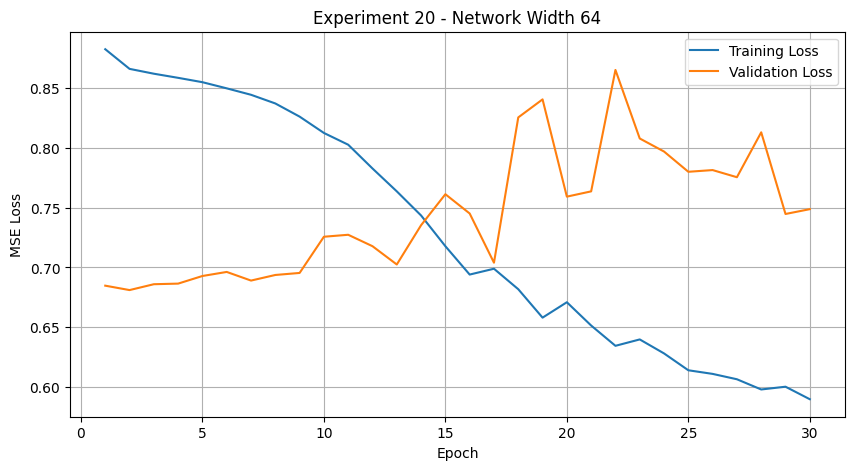

In [309]:
# EXPERIMENT 20 - PLOT TRAINING AND VALIDATION LOSS

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, exp20_epochs + 1),
    exp20_train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, exp20_epochs + 1),
    exp20_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 20 - Network Width 64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [310]:
# EXPERIMENT 21 - DEPTH = 1, NEURONS = 64

# 1. Create a fresh DNN model

class Experiment21Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp21_model = Experiment21Model(input_size=315)

print(exp21_model)

Experiment21Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [311]:
# 3. Create DataLoader

exp21_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# 4. Define loss function

exp21_criterion = nn.MSELoss()

# 5. Define optimizer

exp21_optimizer = optim.Adam(
    exp21_model.parameters(),
    lr=0.001
)

# 6. Set number of epochs

exp21_epochs = 30

# 7. Store training and validation losses

exp21_train_losses = []
exp21_val_losses = []

print("Experiment 21 training setup completed!")

Experiment 21 training setup completed!


In [312]:
# 8. Start training

import time

exp21_start_time = time.time()

for epoch in range(exp21_epochs):

    exp21_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp21_train_loader:

        predictions = exp21_model(X_batch)

        loss = exp21_criterion(predictions, y_batch)

        exp21_optimizer.zero_grad()
        loss.backward()
        exp21_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # 9. Validation

    exp21_model.eval()

    with torch.no_grad():

        val_predictions = exp21_model(X_val_tensor)

        val_loss = exp21_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # 10. Save losses

    exp21_train_losses.append(train_loss)
    exp21_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp21_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# 11. Calculate training time

exp21_training_time = time.time() - exp21_start_time

print(f"Training time: {exp21_training_time:.2f} seconds")

# 12. Display final results

print("Experiment 21 completed!")

print("Final training MSE:", exp21_train_losses[-1])
print("Final validation MSE:", exp21_val_losses[-1])

print(
    "Training time:",
    round(exp21_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.8792, Val Loss: 0.6841
Epoch [2/30], Train Loss: 0.8643, Val Loss: 0.6828
Epoch [3/30], Train Loss: 0.8610, Val Loss: 0.6839
Epoch [4/30], Train Loss: 0.8584, Val Loss: 0.6826
Epoch [5/30], Train Loss: 0.8562, Val Loss: 0.6839
Epoch [6/30], Train Loss: 0.8533, Val Loss: 0.6855
Epoch [7/30], Train Loss: 0.8508, Val Loss: 0.6896
Epoch [8/30], Train Loss: 0.8482, Val Loss: 0.6900
Epoch [9/30], Train Loss: 0.8459, Val Loss: 0.6921
Epoch [10/30], Train Loss: 0.8438, Val Loss: 0.6933
Epoch [11/30], Train Loss: 0.8412, Val Loss: 0.6913
Epoch [12/30], Train Loss: 0.8391, Val Loss: 0.6902
Epoch [13/30], Train Loss: 0.8365, Val Loss: 0.6921
Epoch [14/30], Train Loss: 0.8339, Val Loss: 0.6930
Epoch [15/30], Train Loss: 0.8316, Val Loss: 0.6949
Epoch [16/30], Train Loss: 0.8291, Val Loss: 0.6953
Epoch [17/30], Train Loss: 0.8258, Val Loss: 0.6990
Epoch [18/30], Train Loss: 0.8233, Val Loss: 0.6981
Epoch [19/30], Train Loss: 0.8212, Val Loss: 0.7011
Epoch [20/30], Train 

In [313]:
# EXPERIMENT 21 - EVALUATE MODEL

exp21_model.eval()

with torch.no_grad():

    exp21_val_scaled = exp21_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp21_val_predictions = target_scaler.inverse_transform(
        exp21_val_scaled
    )

    # Calculate validation MSE

    exp21_val_mse = mean_squared_error(
        y_val,
        exp21_val_predictions
    )

print("Experiment 21 Validation MSE:", exp21_val_mse)

Experiment 21 Validation MSE: 4770565120.0


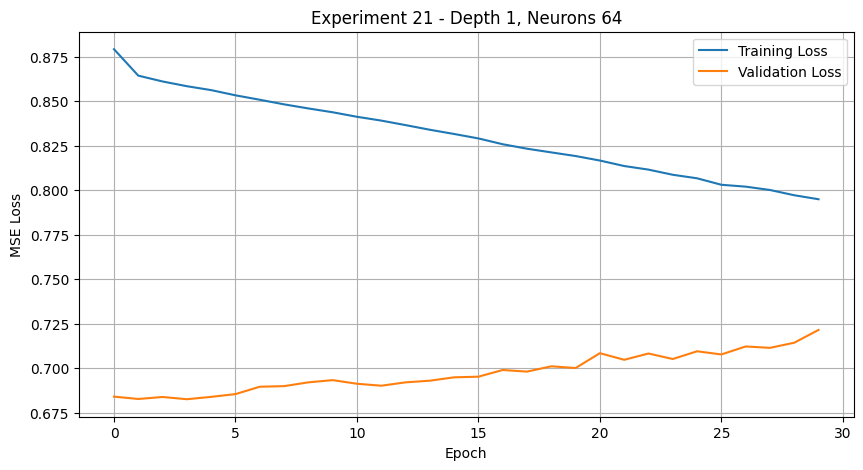

In [314]:
# EXPERIMENT 21 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(exp21_train_losses, label="Training Loss")
plt.plot(exp21_val_losses, label="Validation Loss")

plt.title("Experiment 21 - Depth 1, Neurons 64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [315]:
# EXPERIMENT 22 - DEPTH = 2, NEURONS = 64

# 1. Create a fresh DNN model

class Experiment22Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp22_model = Experiment22Model(input_size=315)

print(exp22_model)

Experiment22Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [316]:
# 3. Create DataLoader

exp22_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# 4. Define loss function

exp22_criterion = nn.MSELoss()

# 5. Define optimizer

exp22_optimizer = optim.Adam(
    exp22_model.parameters(),
    lr=0.001
)

# 6. Set number of epochs

exp22_epochs = 30

# 7. Store training and validation losses

exp22_train_losses = []
exp22_val_losses = []

print("Experiment 22 training setup completed!")

Experiment 22 training setup completed!


In [317]:
# 8. Start training

import time

exp22_start_time = time.time()

for epoch in range(exp22_epochs):

    exp22_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp22_train_loader:

        predictions = exp22_model(X_batch)

        loss = exp22_criterion(predictions, y_batch)

        exp22_optimizer.zero_grad()
        loss.backward()
        exp22_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # 9. Validation

    exp22_model.eval()

    with torch.no_grad():

        val_predictions = exp22_model(X_val_tensor)

        val_loss = exp22_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # 10. Save losses

    exp22_train_losses.append(train_loss)
    exp22_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp22_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# 11. Calculate training time

exp22_training_time = time.time() - exp22_start_time

print(f"Training time: {exp22_training_time:.2f} seconds")

# 12. Display final results

print("Experiment 22 completed!")

print("Final training MSE:", exp22_train_losses[-1])
print("Final validation MSE:", exp22_val_losses[-1])

print(
    "Training time:",
    round(exp22_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.8796, Val Loss: 0.6857
Epoch [2/30], Train Loss: 0.8652, Val Loss: 0.6862
Epoch [3/30], Train Loss: 0.8611, Val Loss: 0.6845
Epoch [4/30], Train Loss: 0.8578, Val Loss: 0.6829
Epoch [5/30], Train Loss: 0.8549, Val Loss: 0.6837
Epoch [6/30], Train Loss: 0.8513, Val Loss: 0.6865
Epoch [7/30], Train Loss: 0.8475, Val Loss: 0.6945
Epoch [8/30], Train Loss: 0.8440, Val Loss: 0.6881
Epoch [9/30], Train Loss: 0.8378, Val Loss: 0.6877
Epoch [10/30], Train Loss: 0.8307, Val Loss: 0.6894
Epoch [11/30], Train Loss: 0.8234, Val Loss: 0.6972
Epoch [12/30], Train Loss: 0.8128, Val Loss: 0.7165
Epoch [13/30], Train Loss: 0.7981, Val Loss: 0.7397
Epoch [14/30], Train Loss: 0.7831, Val Loss: 0.7089
Epoch [15/30], Train Loss: 0.7683, Val Loss: 0.7191
Epoch [16/30], Train Loss: 0.7520, Val Loss: 0.6998
Epoch [17/30], Train Loss: 0.7380, Val Loss: 0.6948
Epoch [18/30], Train Loss: 0.7210, Val Loss: 0.7211
Epoch [19/30], Train Loss: 0.7044, Val Loss: 0.7290
Epoch [20/30], Train 

In [318]:
# EXPERIMENT 22 - EVALUATE MODEL

exp22_model.eval()

with torch.no_grad():

    exp22_val_scaled = exp22_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp22_val_predictions = target_scaler.inverse_transform(
        exp22_val_scaled
    )

    # Calculate validation MSE

    exp22_val_mse = mean_squared_error(
        y_val,
        exp22_val_predictions
    )

print("Experiment 22 Validation MSE:", exp22_val_mse)

Experiment 22 Validation MSE: 4871304192.0


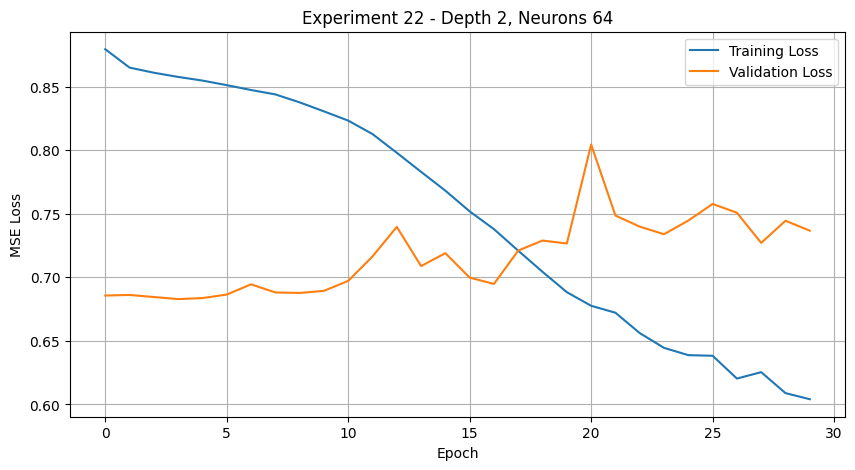

In [319]:
# EXPERIMENT 22 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(exp22_train_losses, label="Training Loss")
plt.plot(exp22_val_losses, label="Validation Loss")

plt.title("Experiment 22 - Depth 2, Neurons 64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [320]:
# EXPERIMENT 23 - DEPTH = 3, NEURONS = 64

# 1. Create a fresh DNN model

class Experiment23Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp23_model = Experiment23Model(input_size=315)

print(exp23_model)

Experiment23Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [321]:
# EXPERIMENT 23 - TRAINING SETUP

# Create DataLoader
exp23_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
exp23_criterion = nn.MSELoss()

# Define optimizer
exp23_optimizer = optim.Adam(
    exp23_model.parameters(),
    lr=0.001
)

# Number of epochs
exp23_epochs = 30

# Store training and validation losses
exp23_train_losses = []
exp23_val_losses = []

print("Experiment 23 training setup completed!")

Experiment 23 training setup completed!


In [322]:
# EXPERIMENT 23 - START TRAINING

import time

exp23_start_time = time.time()

for epoch in range(exp23_epochs):

    exp23_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp23_train_loader:

        predictions = exp23_model(X_batch)

        loss = exp23_criterion(predictions, y_batch)

        exp23_optimizer.zero_grad()
        loss.backward()
        exp23_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp23_model.eval()

    with torch.no_grad():

        val_predictions = exp23_model(X_val_tensor)

        val_loss = exp23_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    exp23_train_losses.append(train_loss)
    exp23_val_losses.append(val_loss)

    # Display results
    print(
        f"Epoch [{epoch+1}/{exp23_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time
exp23_training_time = time.time() - exp23_start_time

print(f"Training time: {exp23_training_time:.2f} seconds")

# Display final results
print("Experiment 23 completed!")

print("Final training MSE:", exp23_train_losses[-1])
print("Final validation MSE:", exp23_val_losses[-1])

print(
    "Training time:",
    round(exp23_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.8815, Val Loss: 0.6863
Epoch [2/30], Train Loss: 0.8666, Val Loss: 0.6847
Epoch [3/30], Train Loss: 0.8612, Val Loss: 0.6845
Epoch [4/30], Train Loss: 0.8572, Val Loss: 0.6833
Epoch [5/30], Train Loss: 0.8542, Val Loss: 0.6842
Epoch [6/30], Train Loss: 0.8478, Val Loss: 0.6885
Epoch [7/30], Train Loss: 0.8443, Val Loss: 0.6906
Epoch [8/30], Train Loss: 0.8367, Val Loss: 0.6933
Epoch [9/30], Train Loss: 0.8260, Val Loss: 0.6983
Epoch [10/30], Train Loss: 0.8158, Val Loss: 0.7014
Epoch [11/30], Train Loss: 0.8038, Val Loss: 0.7094
Epoch [12/30], Train Loss: 0.7788, Val Loss: 0.7573
Epoch [13/30], Train Loss: 0.7528, Val Loss: 0.7508
Epoch [14/30], Train Loss: 0.7362, Val Loss: 0.7582
Epoch [15/30], Train Loss: 0.7117, Val Loss: 0.7392
Epoch [16/30], Train Loss: 0.6921, Val Loss: 0.7369
Epoch [17/30], Train Loss: 0.6785, Val Loss: 0.7533
Epoch [18/30], Train Loss: 0.6776, Val Loss: 0.7361
Epoch [19/30], Train Loss: 0.6625, Val Loss: 0.8216
Epoch [20/30], Train 

In [323]:
# EXPERIMENT 23 - EVALUATE MODEL

exp23_model.eval()

with torch.no_grad():

    exp23_val_scaled = exp23_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp23_val_predictions = target_scaler.inverse_transform(
        exp23_val_scaled
    )

    # Calculate validation MSE
    exp23_val_mse = mean_squared_error(
        y_val,
        exp23_val_predictions
    )

print("Experiment 23 Validation MSE:", exp23_val_mse)

Experiment 23 Validation MSE: 5095318016.0


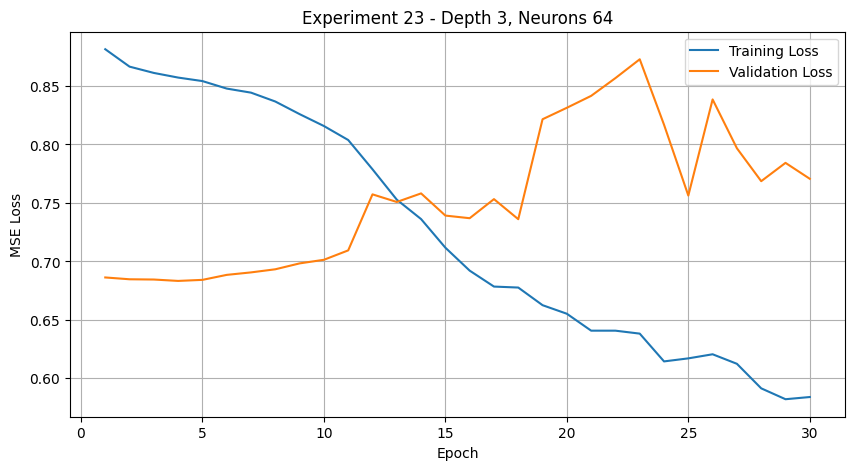

In [324]:
# EXPERIMENT 23 - PLOT TRAINING AND VALIDATION LOSS

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, exp23_epochs + 1),
    exp23_train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, exp23_epochs + 1),
    exp23_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 23 - Depth 3, Neurons 64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [325]:
# EXPERIMENT 24 - DEPTH = 4, WIDTH = 64

# 1. Create a fresh DNN model

class Experiment24Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp24_model = Experiment24Model(input_size=315)

print(exp24_model)

Experiment24Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): ReLU()
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [326]:
# 2. Create DataLoader

exp24_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# 3. Define loss function

exp24_criterion = nn.MSELoss()

# 4. Define optimizer

exp24_optimizer = optim.Adam(
    exp24_model.parameters(),
    lr=0.001
)

# 5. Set number of epochs

exp24_epochs = 30

# Store training and validation losses

exp24_train_losses = []
exp24_val_losses = []

print("Experiment 24 training setup completed!")

Experiment 24 training setup completed!


In [327]:
# 6. Start training

import time

exp24_start_time = time.time()

for epoch in range(exp24_epochs):

    exp24_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp24_train_loader:

        predictions = exp24_model(X_batch)

        loss = exp24_criterion(predictions, y_batch)

        exp24_optimizer.zero_grad()
        loss.backward()
        exp24_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp24_model.eval()

    with torch.no_grad():

        val_predictions = exp24_model(X_val_tensor)

        val_loss = exp24_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp24_train_losses.append(train_loss)
    exp24_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp24_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp24_training_time = time.time() - exp24_start_time

print(f"Training time: {exp24_training_time:.2f} seconds")

# Display final results

print("Experiment 24 completed!")

print("Final training MSE:", exp24_train_losses[-1])
print("Final validation MSE:", exp24_val_losses[-1])

print(
    "Training time:",
    round(exp24_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.8838, Val Loss: 0.6852
Epoch [2/30], Train Loss: 0.8668, Val Loss: 0.6847
Epoch [3/30], Train Loss: 0.8628, Val Loss: 0.6866
Epoch [4/30], Train Loss: 0.8595, Val Loss: 0.6860
Epoch [5/30], Train Loss: 0.8561, Val Loss: 0.6860
Epoch [6/30], Train Loss: 0.8518, Val Loss: 0.6829
Epoch [7/30], Train Loss: 0.8460, Val Loss: 0.6856
Epoch [8/30], Train Loss: 0.8402, Val Loss: 0.6881
Epoch [9/30], Train Loss: 0.8316, Val Loss: 0.7188
Epoch [10/30], Train Loss: 0.8211, Val Loss: 0.6937
Epoch [11/30], Train Loss: 0.8026, Val Loss: 0.6948
Epoch [12/30], Train Loss: 0.7785, Val Loss: 0.7099
Epoch [13/30], Train Loss: 0.7553, Val Loss: 0.7056
Epoch [14/30], Train Loss: 0.7429, Val Loss: 0.7076
Epoch [15/30], Train Loss: 0.7179, Val Loss: 0.6989
Epoch [16/30], Train Loss: 0.6976, Val Loss: 0.7468
Epoch [17/30], Train Loss: 0.6907, Val Loss: 0.7289
Epoch [18/30], Train Loss: 0.6774, Val Loss: 0.8115
Epoch [19/30], Train Loss: 0.6687, Val Loss: 0.7131
Epoch [20/30], Train 

In [328]:
# EXPERIMENT 24 - EVALUATE MODEL

exp24_model.eval()

with torch.no_grad():

    exp24_val_scaled = exp24_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp24_val_predictions = target_scaler.inverse_transform(
        exp24_val_scaled
    )

    # Calculate validation MSE

    exp24_val_mse = mean_squared_error(
        y_val,
        exp24_val_predictions
    )

print("Experiment 24 Validation MSE:", exp24_val_mse)

Experiment 24 Validation MSE: 5245039616.0


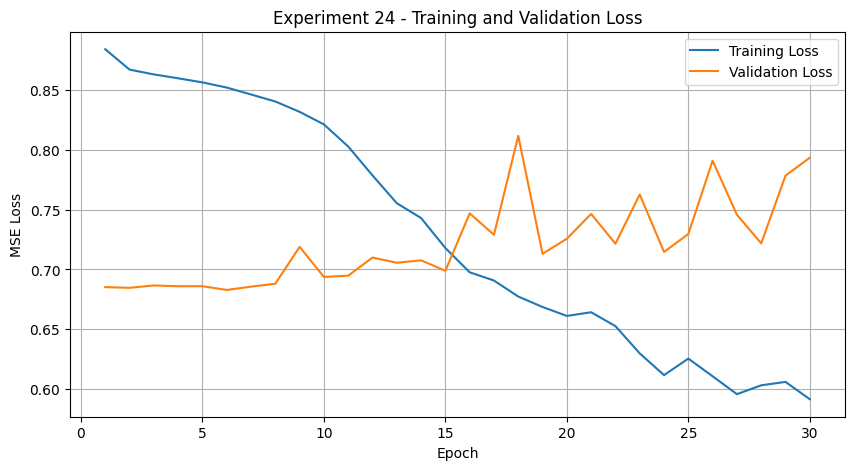

In [329]:
# EXPERIMENT 24 - PLOT TRAINING AND VALIDATION LOSS

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, exp24_epochs + 1),
    exp24_train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, exp24_epochs + 1),
    exp24_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 24 - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [330]:
# EXPERIMENT 25 - MSE LOSS
# Hidden Layers = 2
# Neurons = 64

# 1. Create a fresh DNN model

class Experiment25Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp25_model = Experiment25Model(input_size=315)

print(exp25_model)

Experiment25Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [331]:
# EXPERIMENT 25 - TRAINING SETUP

# Create DataLoader

exp25_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function

exp25_criterion = nn.MSELoss()

# Define optimizer

exp25_optimizer = optim.Adam(
    exp25_model.parameters(),
    lr=0.001
)

# Number of epochs

exp25_epochs = 30

# Store training and validation losses

exp25_train_losses = []
exp25_val_losses = []

print("Experiment 25 training setup completed!")

Experiment 25 training setup completed!


In [332]:
# EXPERIMENT 25 - START TRAINING

import time

exp25_start_time = time.time()

for epoch in range(exp25_epochs):

    exp25_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp25_train_loader:

        predictions = exp25_model(X_batch)

        loss = exp25_criterion(predictions, y_batch)

        exp25_optimizer.zero_grad()
        loss.backward()
        exp25_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp25_model.eval()

    with torch.no_grad():

        val_predictions = exp25_model(X_val_tensor)

        val_loss = exp25_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp25_train_losses.append(train_loss)
    exp25_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp25_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp25_training_time = time.time() - exp25_start_time

print(f"Training time: {exp25_training_time:.2f} seconds")

# Display final results

print("Experiment 25 completed!")

print("Final training MSE:", exp25_train_losses[-1])
print("Final validation MSE:", exp25_val_losses[-1])

print(
    "Training time:",
    round(exp25_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.8808, Val Loss: 0.6834
Epoch [2/30], Train Loss: 0.8656, Val Loss: 0.6831
Epoch [3/30], Train Loss: 0.8609, Val Loss: 0.6845
Epoch [4/30], Train Loss: 0.8576, Val Loss: 0.6825
Epoch [5/30], Train Loss: 0.8534, Val Loss: 0.6858
Epoch [6/30], Train Loss: 0.8497, Val Loss: 0.6896
Epoch [7/30], Train Loss: 0.8444, Val Loss: 0.6976
Epoch [8/30], Train Loss: 0.8408, Val Loss: 0.6909
Epoch [9/30], Train Loss: 0.8336, Val Loss: 0.6940
Epoch [10/30], Train Loss: 0.8287, Val Loss: 0.6990
Epoch [11/30], Train Loss: 0.8182, Val Loss: 0.6962
Epoch [12/30], Train Loss: 0.8083, Val Loss: 0.7010
Epoch [13/30], Train Loss: 0.7962, Val Loss: 0.6988
Epoch [14/30], Train Loss: 0.7787, Val Loss: 0.7117
Epoch [15/30], Train Loss: 0.7673, Val Loss: 0.7158
Epoch [16/30], Train Loss: 0.7494, Val Loss: 0.7299
Epoch [17/30], Train Loss: 0.7351, Val Loss: 0.7338
Epoch [18/30], Train Loss: 0.7207, Val Loss: 0.7237
Epoch [19/30], Train Loss: 0.7022, Val Loss: 0.8273
Epoch [20/30], Train 

In [333]:
# EXPERIMENT 25 - EVALUATE MODEL

exp25_model.eval()

with torch.no_grad():

    exp25_val_scaled = exp25_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp25_val_predictions = target_scaler.inverse_transform(
        exp25_val_scaled
    )

    # Calculate validation MSE

    exp25_val_mse = mean_squared_error(
        y_val,
        exp25_val_predictions
    )

print("Experiment 25 Validation MSE:", exp25_val_mse)

Experiment 25 Validation MSE: 5274654208.0


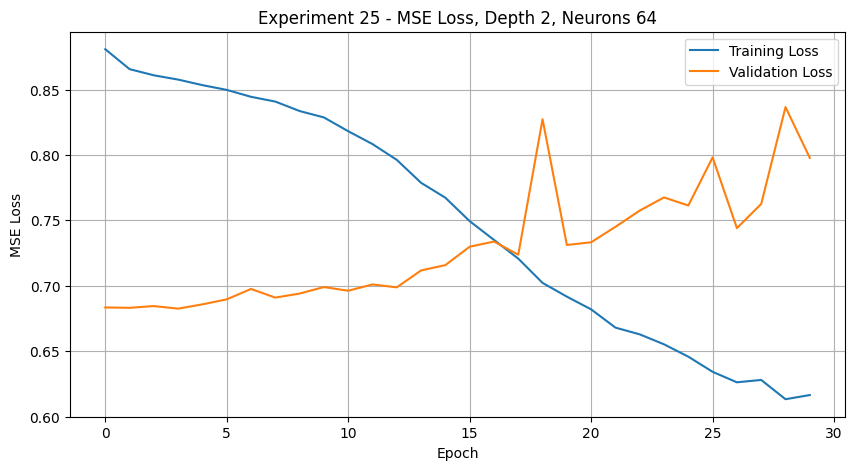

In [334]:
# EXPERIMENT 25 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(exp25_train_losses, label="Training Loss")
plt.plot(exp25_val_losses, label="Validation Loss")

plt.title("Experiment 25 - MSE Loss, Depth 2, Neurons 64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [335]:
# EXPERIMENT 26 - L1 LOSS
# Hidden Layers = 2
# Neurons = 64

# 1. Create a fresh DNN model

class Experiment26Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp26_model = Experiment26Model(input_size=315)

print(exp26_model)

Experiment26Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [336]:
# EXPERIMENT 26 - TRAINING SETUP

# Create DataLoader

exp26_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define L1 loss function

exp26_criterion = nn.L1Loss()

# Define MSE for validation comparison

exp26_mse_criterion = nn.MSELoss()

# Define optimizer

exp26_optimizer = optim.Adam(
    exp26_model.parameters(),
    lr=0.001
)

# Number of epochs

exp26_epochs = 30

# Store training and validation losses

exp26_train_losses = []
exp26_val_losses = []
exp26_val_mse_scores = []

print("Experiment 26 training setup completed!")

Experiment 26 training setup completed!


In [337]:
# EXPERIMENT 26 - START TRAINING

import time

exp26_start_time = time.time()

for epoch in range(exp26_epochs):

    exp26_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp26_train_loader:

        predictions = exp26_model(X_batch)

        loss = exp26_criterion(predictions, y_batch)

        exp26_optimizer.zero_grad()
        loss.backward()
        exp26_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp26_model.eval()

    with torch.no_grad():

        val_predictions = exp26_model(X_val_tensor)

        # Calculate validation L1 loss

        val_loss = exp26_criterion(
            val_predictions,
            y_val_tensor
        ).item()

        # Calculate validation MSE

        val_mse = exp26_mse_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp26_train_losses.append(train_loss)
    exp26_val_losses.append(val_loss)
    exp26_val_mse_scores.append(val_mse)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp26_epochs}], "
        f"Train L1 Loss: {train_loss:.4f}, "
        f"Val L1 Loss: {val_loss:.4f}, "
        f"Val MSE: {val_mse:.4f}"
    )

# Calculate training time

exp26_training_time = time.time() - exp26_start_time

print(f"Training time: {exp26_training_time:.2f} seconds")

# Display final results

print("Experiment 26 completed!")

print("Final training L1 Loss:", exp26_train_losses[-1])
print("Final validation L1 Loss:", exp26_val_losses[-1])
print("Final validation MSE (scaled):", exp26_val_mse_scores[-1])

print(
    "Training time:",
    round(exp26_training_time, 2),
    "seconds"
)

Epoch [1/30], Train L1 Loss: 0.2257, Val L1 Loss: 0.2190, Val MSE: 0.7036
Epoch [2/30], Train L1 Loss: 0.2185, Val L1 Loss: 0.2183, Val MSE: 0.7084
Epoch [3/30], Train L1 Loss: 0.2171, Val L1 Loss: 0.2191, Val MSE: 0.6976
Epoch [4/30], Train L1 Loss: 0.2164, Val L1 Loss: 0.2176, Val MSE: 0.7001
Epoch [5/30], Train L1 Loss: 0.2154, Val L1 Loss: 0.2179, Val MSE: 0.7067
Epoch [6/30], Train L1 Loss: 0.2147, Val L1 Loss: 0.2175, Val MSE: 0.7047
Epoch [7/30], Train L1 Loss: 0.2140, Val L1 Loss: 0.2181, Val MSE: 0.7009
Epoch [8/30], Train L1 Loss: 0.2134, Val L1 Loss: 0.2180, Val MSE: 0.7026
Epoch [9/30], Train L1 Loss: 0.2128, Val L1 Loss: 0.2184, Val MSE: 0.7019
Epoch [10/30], Train L1 Loss: 0.2121, Val L1 Loss: 0.2186, Val MSE: 0.7006
Epoch [11/30], Train L1 Loss: 0.2117, Val L1 Loss: 0.2192, Val MSE: 0.6986
Epoch [12/30], Train L1 Loss: 0.2110, Val L1 Loss: 0.2185, Val MSE: 0.7015
Epoch [13/30], Train L1 Loss: 0.2105, Val L1 Loss: 0.2199, Val MSE: 0.7125
Epoch [14/30], Train L1 Loss: 0.20

In [338]:
# EXPERIMENT 26 - EVALUATE MODEL

exp26_model.eval()

with torch.no_grad():

    exp26_val_scaled = exp26_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp26_val_predictions = target_scaler.inverse_transform(
        exp26_val_scaled
    )

    # Calculate validation MSE in original price scale

    exp26_val_mse_original = mean_squared_error(
        y_val,
        exp26_val_predictions
    )

print(
    "Experiment 26 Validation MSE (original scale):",
    exp26_val_mse_original
)

Experiment 26 Validation MSE (original scale): 4654075904.0


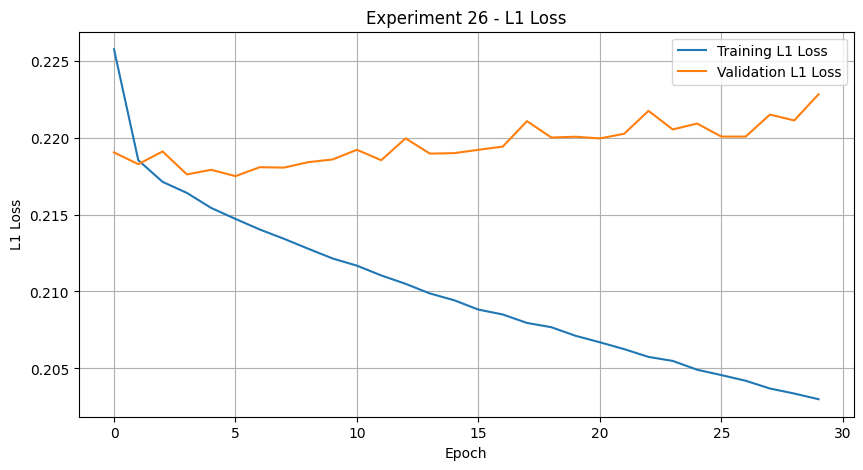

In [339]:
# EXPERIMENT 26 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp26_train_losses,
    label="Training L1 Loss"
)

plt.plot(
    exp26_val_losses,
    label="Validation L1 Loss"
)

plt.title("Experiment 26 - L1 Loss")
plt.xlabel("Epoch")
plt.ylabel("L1 Loss")

plt.legend()
plt.grid(True)

plt.show()

In [340]:
# EXPERIMENT 27 - HUBER LOSS (DELTA = 0.5)
# Hidden Layers = 2
# Neurons = 64

# 1. Create a fresh DNN model

class Experiment27Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp27_model = Experiment27Model(input_size=315)

print(exp27_model)

Experiment27Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [341]:
# EXPERIMENT 27 - TRAINING SETUP

# Create DataLoader

exp27_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define Huber loss function

exp27_criterion = nn.HuberLoss(delta=0.5)

# Define optimizer

exp27_optimizer = optim.Adam(
    exp27_model.parameters(),
    lr=0.001
)

# Set number of epochs

exp27_epochs = 30

# Store training and validation losses

exp27_train_losses = []
exp27_val_losses = []

print("Experiment 27 training setup completed!")

Experiment 27 training setup completed!


In [342]:
# EXPERIMENT 27 - START TRAINING

import time

exp27_start_time = time.time()

for epoch in range(exp27_epochs):

    exp27_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp27_train_loader:

        predictions = exp27_model(X_batch)

        loss = exp27_criterion(predictions, y_batch)

        exp27_optimizer.zero_grad()
        loss.backward()
        exp27_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp27_model.eval()

    with torch.no_grad():

        val_predictions = exp27_model(X_val_tensor)

        val_loss = exp27_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp27_train_losses.append(train_loss)
    exp27_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp27_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp27_training_time = time.time() - exp27_start_time

print(f"Training time: {exp27_training_time:.2f} seconds")

# Display final results

print("Experiment 27 completed!")

print("Final training Huber Loss:", exp27_train_losses[-1])
print("Final validation Huber Loss:", exp27_val_losses[-1])

print(
    "Training time:",
    round(exp27_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.0617, Val Loss: 0.0598
Epoch [2/30], Train Loss: 0.0597, Val Loss: 0.0598
Epoch [3/30], Train Loss: 0.0593, Val Loss: 0.0596
Epoch [4/30], Train Loss: 0.0591, Val Loss: 0.0597
Epoch [5/30], Train Loss: 0.0588, Val Loss: 0.0596
Epoch [6/30], Train Loss: 0.0585, Val Loss: 0.0598
Epoch [7/30], Train Loss: 0.0583, Val Loss: 0.0597
Epoch [8/30], Train Loss: 0.0580, Val Loss: 0.0596
Epoch [9/30], Train Loss: 0.0577, Val Loss: 0.0597
Epoch [10/30], Train Loss: 0.0575, Val Loss: 0.0599
Epoch [11/30], Train Loss: 0.0573, Val Loss: 0.0602
Epoch [12/30], Train Loss: 0.0570, Val Loss: 0.0601
Epoch [13/30], Train Loss: 0.0568, Val Loss: 0.0604
Epoch [14/30], Train Loss: 0.0566, Val Loss: 0.0605
Epoch [15/30], Train Loss: 0.0563, Val Loss: 0.0600
Epoch [16/30], Train Loss: 0.0560, Val Loss: 0.0609
Epoch [17/30], Train Loss: 0.0559, Val Loss: 0.0610
Epoch [18/30], Train Loss: 0.0556, Val Loss: 0.0609
Epoch [19/30], Train Loss: 0.0554, Val Loss: 0.0610
Epoch [20/30], Train 

In [343]:
# EXPERIMENT 27 - EVALUATE MODEL

exp27_model.eval()

with torch.no_grad():

    exp27_val_scaled = exp27_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp27_val_predictions = target_scaler.inverse_transform(
        exp27_val_scaled
    )

    # Calculate validation MSE

    exp27_val_mse = mean_squared_error(
        y_val,
        exp27_val_predictions
    )

print("Experiment 27 Validation MSE:", exp27_val_mse)

Experiment 27 Validation MSE: 4680361984.0


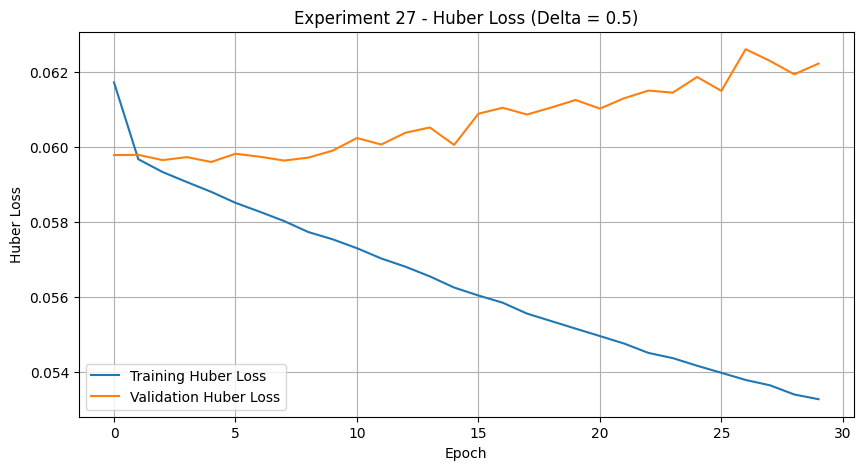

In [344]:
# EXPERIMENT 27 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp27_train_losses,
    label="Training Huber Loss"
)

plt.plot(
    exp27_val_losses,
    label="Validation Huber Loss"
)

plt.title("Experiment 27 - Huber Loss (Delta = 0.5)")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")

plt.legend()
plt.grid(True)

plt.show()

In [345]:
# EXPERIMENT 28 - HUBER LOSS (DELTA = 1.0)

# 1. Create a fresh DNN model

class Experiment28Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp28_model = Experiment28Model(input_size=315)

print(exp28_model)

Experiment28Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [346]:
# EXPERIMENT 28 - TRAINING SETUP

# Create DataLoader

exp28_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define Huber loss function

exp28_criterion = nn.HuberLoss(delta=1.0)

# Define optimizer

exp28_optimizer = optim.Adam(
    exp28_model.parameters(),
    lr=0.001
)

# Number of epochs

exp28_epochs = 30

# Store training and validation losses

exp28_train_losses = []
exp28_val_losses = []

print("Experiment 28 training setup completed!")

Experiment 28 training setup completed!


In [347]:
# EXPERIMENT 28 - START TRAINING

import time

exp28_start_time = time.time()

for epoch in range(exp28_epochs):

    exp28_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp28_train_loader:

        predictions = exp28_model(X_batch)

        loss = exp28_criterion(predictions, y_batch)

        exp28_optimizer.zero_grad()
        loss.backward()
        exp28_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp28_model.eval()

    with torch.no_grad():

        val_predictions = exp28_model(X_val_tensor)

        val_loss = exp28_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp28_train_losses.append(train_loss)
    exp28_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp28_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp28_training_time = time.time() - exp28_start_time

print(f"Training time: {exp28_training_time:.2f} seconds")

# Display final results

print("Experiment 28 completed!")

print("Final training Huber Loss:", exp28_train_losses[-1])
print("Final validation Huber Loss:", exp28_val_losses[-1])

print(
    "Training time:",
    round(exp28_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.0951, Val Loss: 0.0927
Epoch [2/30], Train Loss: 0.0926, Val Loss: 0.0925
Epoch [3/30], Train Loss: 0.0922, Val Loss: 0.0925
Epoch [4/30], Train Loss: 0.0917, Val Loss: 0.0923
Epoch [5/30], Train Loss: 0.0914, Val Loss: 0.0925
Epoch [6/30], Train Loss: 0.0909, Val Loss: 0.0926
Epoch [7/30], Train Loss: 0.0905, Val Loss: 0.0924
Epoch [8/30], Train Loss: 0.0902, Val Loss: 0.0927
Epoch [9/30], Train Loss: 0.0898, Val Loss: 0.0928
Epoch [10/30], Train Loss: 0.0894, Val Loss: 0.0929
Epoch [11/30], Train Loss: 0.0890, Val Loss: 0.0931
Epoch [12/30], Train Loss: 0.0886, Val Loss: 0.0935
Epoch [13/30], Train Loss: 0.0883, Val Loss: 0.0941
Epoch [14/30], Train Loss: 0.0878, Val Loss: 0.0943
Epoch [15/30], Train Loss: 0.0875, Val Loss: 0.0939
Epoch [16/30], Train Loss: 0.0869, Val Loss: 0.0938
Epoch [17/30], Train Loss: 0.0866, Val Loss: 0.0942
Epoch [18/30], Train Loss: 0.0862, Val Loss: 0.0949
Epoch [19/30], Train Loss: 0.0857, Val Loss: 0.0950
Epoch [20/30], Train 

In [348]:
# EXPERIMENT 28 - EVALUATE MODEL

exp28_model.eval()

with torch.no_grad():

    exp28_val_scaled = exp28_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp28_val_predictions = target_scaler.inverse_transform(
        exp28_val_scaled
    )

    # Calculate validation MSE

    exp28_val_mse = mean_squared_error(
        y_val,
        exp28_val_predictions
    )

print("Experiment 28 Validation MSE:", exp28_val_mse)

Experiment 28 Validation MSE: 4661761536.0


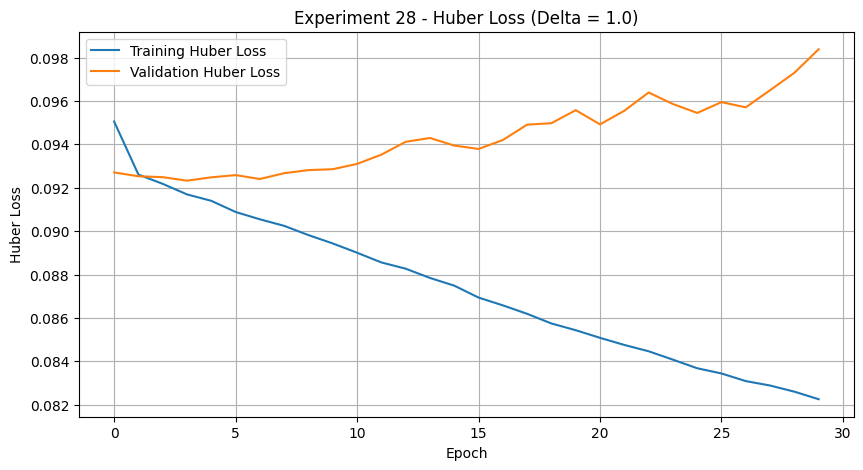

In [349]:
# EXPERIMENT 28 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp28_train_losses,
    label="Training Huber Loss"
)

plt.plot(
    exp28_val_losses,
    label="Validation Huber Loss"
)

plt.title("Experiment 28 - Huber Loss (Delta = 1.0)")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")

plt.legend()
plt.grid(True)

plt.show()

In [350]:
# EXPERIMENT 29 - HUBER LOSS (DELTA = 2.0)

# 1. Create a fresh DNN model

class Experiment29Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp29_model = Experiment29Model(input_size=315)

print(exp29_model)

Experiment29Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [351]:
# EXPERIMENT 29 - TRAINING SETUP

# Create DataLoader

exp29_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define Huber loss function

exp29_criterion = nn.HuberLoss(delta=2.0)

# Define optimizer

exp29_optimizer = optim.Adam(
    exp29_model.parameters(),
    lr=0.001
)

# Number of epochs

exp29_epochs = 30

# Store training and validation losses

exp29_train_losses = []
exp29_val_losses = []

print("Experiment 29 training setup completed!")

Experiment 29 training setup completed!


In [352]:
# EXPERIMENT 29 - START TRAINING

import time

exp29_start_time = time.time()

for epoch in range(exp29_epochs):

    exp29_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp29_train_loader:

        predictions = exp29_model(X_batch)

        loss = exp29_criterion(predictions, y_batch)

        exp29_optimizer.zero_grad()
        loss.backward()
        exp29_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp29_model.eval()

    with torch.no_grad():

        val_predictions = exp29_model(X_val_tensor)

        val_loss = exp29_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp29_train_losses.append(train_loss)
    exp29_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp29_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp29_training_time = time.time() - exp29_start_time

print(f"Training time: {exp29_training_time:.2f} seconds")

# Display final results

print("Experiment 29 completed!")

print("Final training Huber Loss:", exp29_train_losses[-1])
print("Final validation Huber Loss:", exp29_val_losses[-1])

print(
    "Training time:",
    round(exp29_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.1412, Val Loss: 0.1366
Epoch [2/30], Train Loss: 0.1374, Val Loss: 0.1358
Epoch [3/30], Train Loss: 0.1370, Val Loss: 0.1351
Epoch [4/30], Train Loss: 0.1363, Val Loss: 0.1353
Epoch [5/30], Train Loss: 0.1357, Val Loss: 0.1360
Epoch [6/30], Train Loss: 0.1351, Val Loss: 0.1354
Epoch [7/30], Train Loss: 0.1344, Val Loss: 0.1362
Epoch [8/30], Train Loss: 0.1341, Val Loss: 0.1361
Epoch [9/30], Train Loss: 0.1332, Val Loss: 0.1370
Epoch [10/30], Train Loss: 0.1327, Val Loss: 0.1371
Epoch [11/30], Train Loss: 0.1320, Val Loss: 0.1374
Epoch [12/30], Train Loss: 0.1314, Val Loss: 0.1379
Epoch [13/30], Train Loss: 0.1308, Val Loss: 0.1374
Epoch [14/30], Train Loss: 0.1301, Val Loss: 0.1406
Epoch [15/30], Train Loss: 0.1294, Val Loss: 0.1384
Epoch [16/30], Train Loss: 0.1287, Val Loss: 0.1393
Epoch [17/30], Train Loss: 0.1280, Val Loss: 0.1390
Epoch [18/30], Train Loss: 0.1272, Val Loss: 0.1383
Epoch [19/30], Train Loss: 0.1266, Val Loss: 0.1429
Epoch [20/30], Train 

In [353]:
# EXPERIMENT 29 - EVALUATE MODEL

exp29_model.eval()

with torch.no_grad():

    exp29_val_scaled = exp29_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp29_val_predictions = target_scaler.inverse_transform(
        exp29_val_scaled
    )

    # Calculate validation MSE

    exp29_val_mse = mean_squared_error(
        y_val,
        exp29_val_predictions
    )

print("Experiment 29 Validation MSE:", exp29_val_mse)

Experiment 29 Validation MSE: 4705344512.0


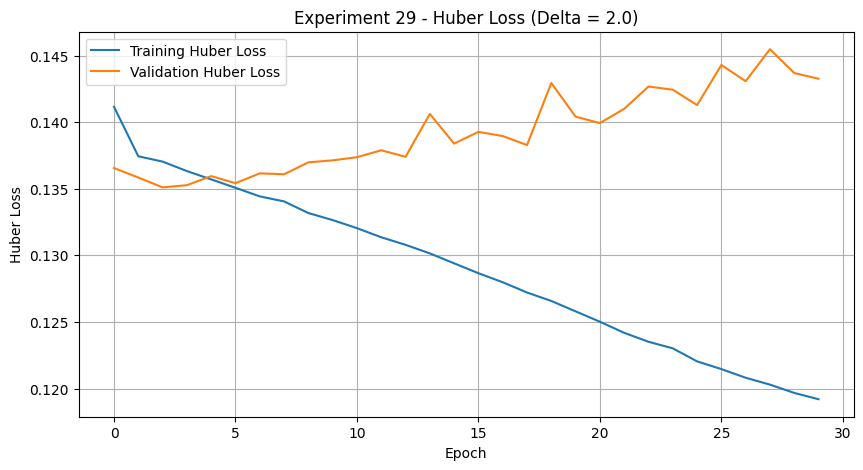

In [354]:
# EXPERIMENT 29 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp29_train_losses,
    label="Training Huber Loss"
)

plt.plot(
    exp29_val_losses,
    label="Validation Huber Loss"
)

plt.title("Experiment 29 - Huber Loss (Delta = 2.0)")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")

plt.legend()
plt.grid(True)

plt.show()

In [355]:
# EXPERIMENT 30 - HUBER LOSS (DELTA = 0.25)

# 1. Create a fresh DNN model

class Experiment30Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp30_model = Experiment30Model(input_size=315)

print(exp30_model)

Experiment30Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [356]:
# EXPERIMENT 30 - TRAINING SETUP

# Create DataLoader

exp30_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define Huber loss function

exp30_criterion = nn.HuberLoss(delta=0.25)

# Define optimizer

exp30_optimizer = optim.Adam(
    exp30_model.parameters(),
    lr=0.001
)

# Number of epochs

exp30_epochs = 30

# Store training and validation losses

exp30_train_losses = []
exp30_val_losses = []

print("Experiment 30 training setup completed!")

Experiment 30 training setup completed!


In [357]:
# EXPERIMENT 30 - START TRAINING

import time

exp30_start_time = time.time()

for epoch in range(exp30_epochs):

    exp30_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp30_train_loader:

        predictions = exp30_model(X_batch)

        loss = exp30_criterion(predictions, y_batch)

        exp30_optimizer.zero_grad()
        loss.backward()
        exp30_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp30_model.eval()

    with torch.no_grad():

        val_predictions = exp30_model(X_val_tensor)

        val_loss = exp30_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp30_train_losses.append(train_loss)
    exp30_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp30_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp30_training_time = time.time() - exp30_start_time

print(f"Training time: {exp30_training_time:.2f} seconds")

# Display final results

print("Experiment 30 completed!")

print("Final training Huber Loss:", exp30_train_losses[-1])
print("Final validation Huber Loss:", exp30_val_losses[-1])

print(
    "Training time:",
    round(exp30_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.0384, Val Loss: 0.0370
Epoch [2/30], Train Loss: 0.0368, Val Loss: 0.0368
Epoch [3/30], Train Loss: 0.0366, Val Loss: 0.0368
Epoch [4/30], Train Loss: 0.0364, Val Loss: 0.0369
Epoch [5/30], Train Loss: 0.0363, Val Loss: 0.0369
Epoch [6/30], Train Loss: 0.0361, Val Loss: 0.0368
Epoch [7/30], Train Loss: 0.0360, Val Loss: 0.0368
Epoch [8/30], Train Loss: 0.0358, Val Loss: 0.0369
Epoch [9/30], Train Loss: 0.0356, Val Loss: 0.0369
Epoch [10/30], Train Loss: 0.0355, Val Loss: 0.0369
Epoch [11/30], Train Loss: 0.0354, Val Loss: 0.0369
Epoch [12/30], Train Loss: 0.0353, Val Loss: 0.0370
Epoch [13/30], Train Loss: 0.0351, Val Loss: 0.0371
Epoch [14/30], Train Loss: 0.0350, Val Loss: 0.0373
Epoch [15/30], Train Loss: 0.0349, Val Loss: 0.0370
Epoch [16/30], Train Loss: 0.0348, Val Loss: 0.0373
Epoch [17/30], Train Loss: 0.0346, Val Loss: 0.0372
Epoch [18/30], Train Loss: 0.0346, Val Loss: 0.0374
Epoch [19/30], Train Loss: 0.0344, Val Loss: 0.0373
Epoch [20/30], Train 

In [358]:
# EXPERIMENT 30 - EVALUATE MODEL

exp30_model.eval()

with torch.no_grad():

    exp30_val_scaled = exp30_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp30_val_predictions = target_scaler.inverse_transform(
        exp30_val_scaled
    )

    # Calculate validation MSE

    exp30_val_mse = mean_squared_error(
        y_val,
        exp30_val_predictions
    )

print("Experiment 30 Validation MSE:", exp30_val_mse)

Experiment 30 Validation MSE: 4671763968.0


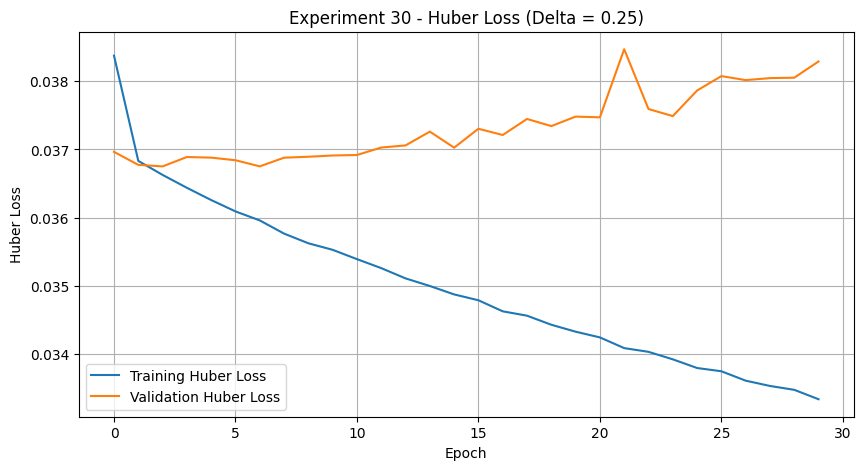

In [359]:
# EXPERIMENT 30 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp30_train_losses,
    label="Training Huber Loss"
)

plt.plot(
    exp30_val_losses,
    label="Validation Huber Loss"
)

plt.title("Experiment 30 - Huber Loss (Delta = 0.25)")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")

plt.legend()
plt.grid(True)

plt.show()

In [360]:
# STEP 4: SELECT THE BEST MODEL USING VALIDATION MSE ONLY

# All validation MSE values below are calculated on the original price scale.
# The test set is NOT used to select the model.

validation_mse = {
    1: exp1_val_mse,
    2: exp2_val_mse,
    3: exp3_val_mse,
    4: exp4_val_mse,
    5: exp5_val_mse,
    6: exp6_val_mse,
    7: exp7_val_mse,
    8: exp8_val_mse,
    9: exp9_val_mse,
    10: exp10_val_mse,
    11: exp11_val_mse,
    12: exp12_val_mse,
    13: exp13_val_mse,
    14: exp14_val_mse,
    15: exp15_val_mse,
    16: exp16_val_mse,
    17: exp17_val_mse,
    18: exp18_val_mse,
    19: exp19_val_mse,
    20: exp20_val_mse,
    21: exp21_val_mse,
    22: exp22_val_mse,
    23: exp23_val_mse,
    24: exp24_val_mse,
    25: exp25_val_mse,
    26: exp26_val_mse_original,
    27: exp27_val_mse,
    28: exp28_val_mse,
    29: exp29_val_mse,
    30: exp30_val_mse
}

experiment_models = {
    1: exp1_model,
    2: exp2_model,
    3: exp3_model,
    4: exp4_model,
    5: exp5_model,
    6: exp6_model,
    7: exp7_model,
    8: exp8_model,
    9: exp9_model,
    10: exp10_model,
    11: exp11_model,
    12: exp12_model,
    13: exp13_model,
    14: exp14_model,
    15: exp15_model,
    16: exp16_model,
    17: exp17_model,
    18: exp18_model,
    19: exp19_model,
    20: exp20_model,
    21: exp21_model,
    22: exp22_model,
    23: exp23_model,
    24: exp24_model,
    25: exp25_model,
    26: exp26_model,
    27: exp27_model,
    28: exp28_model,
    29: exp29_model,
    30: exp30_model
}

# Select the experiment with the lowest validation MSE.
best_experiment = min(validation_mse, key=validation_mse.get)
best_model = experiment_models[best_experiment]
best_validation_mse = validation_mse[best_experiment]

# Compare the selected model with the Linear Regression baseline.
improvement = (
    (linear_val_mse - best_validation_mse) / linear_val_mse
) * 100

print("STEP 4: FINAL MODEL SELECTION")
print("--------------------------------")
print("Selected experiment:", best_experiment)
print("Best validation MSE:", best_validation_mse)
print("Linear Regression validation MSE:", linear_val_mse)
print(f"Improvement over Linear Regression: {improvement:.2f}%")

# Evaluate the selected model on the test set ONCE, after model selection.
best_model.eval()

with torch.no_grad():
    test_predictions_scaled = best_model(X_test_tensor).cpu().numpy()

# Convert predictions back to the original price scale.
test_predictions = target_scaler.inverse_transform(
    test_predictions_scaled
)

test_mse = mean_squared_error(y_test, test_predictions)

print("Test MSE:", test_mse)


STEP 4: FINAL MODEL SELECTION
--------------------------------
Selected experiment: 9
Best validation MSE: 4515515392.0
Linear Regression validation MSE: 4687364096.0
Improvement over Linear Regression: 3.67%
Test MSE: 4355402752.0


In [361]:

# ==========================================
# EXPERIMENTS RESULTS TABLE (30 EXPERIMENTS)
# ==========================================

import pandas as pd

# Store all experiment results
experiments = [
    [1, "Learning Rate", "Adam, lr = 0.00001", exp1_val_mse, "Low learning rate"],
    [2, "Learning Rate", "Adam, lr = 0.0001", exp2_val_mse, "Low learning rate"],
    [3, "Learning Rate", "Adam, lr = 0.0005", exp3_val_mse, "Higher validation error"],
    [4, "Learning Rate", "Adam, lr = 0.001", exp4_val_mse, "Higher validation error"],
    [5, "Learning Rate", "Adam, lr = 0.01", exp5_val_mse, "Performance improved"],
    [6, "Learning Rate", "Adam, lr = 0.1", exp6_val_mse, "Poor validation performance"],

    [7, "Optimizer", "Adam, lr = 0.001", exp7_val_mse, "Best validation result"],
    [8, "Optimizer", "SGD, lr = 0.001", exp8_val_mse, "Higher error than Adam"],
    [9, "Optimizer", "SGD + Momentum 0.9", exp9_val_mse, "Close to Adam"],

    [10, "Batch Size", "Batch = 16", exp10_val_mse, "High validation error"],
    [11, "Batch Size", "Batch = 32", exp11_val_mse, "Higher validation error"],
    [12, "Batch Size", "Batch = 64", exp12_val_mse, "Higher validation error"],
    [13, "Batch Size", "Batch = 128", exp13_val_mse, "Higher validation error"],
    [14, "Batch Size", "Batch = 256", exp14_val_mse, "Best in batch-size group"],
    [15, "Batch Size", "Batch = 512", exp15_val_mse, "Slightly higher error"],
    [16, "Batch Size", "Batch = 8", exp16_val_mse, "Higher validation error"],

    [17, "Network Width", "128 neurons per layer", exp17_val_mse, "Larger network"],
    [18, "Network Width", "32 neurons per layer", exp18_val_mse, "Smaller network"],
    [19, "Network Width", "16 neurons per layer", exp19_val_mse, "Narrow network"],
    [20, "Network Width", "64 neurons per layer", exp20_val_mse, "Moderate network width"],

    [21, "Network Depth", "1 hidden layer, 64 neurons", exp21_val_mse, "Shallow network"],
    [22, "Network Depth", "2 hidden layers, 64 neurons", exp22_val_mse, "Two hidden layers"],
    [23, "Network Depth", "3 hidden layers, 64 neurons", exp23_val_mse, "Three hidden layers"],
    [24, "Network Depth", "4 hidden layers, 64 neurons", exp24_val_mse, "Deeper network"],

    [25, "Loss Function", "MSE Loss", exp25_val_mse, "MSE reference"],
    [26, "Loss Function", "L1 Loss", exp26_val_mse_original, "L1 loss"],
    [27, "Loss Function", "Huber Loss, delta = 0.5", exp27_val_mse, "Robust loss"],
    [28, "Loss Function", "Huber Loss, delta = 1.0", exp28_val_mse, "Huber loss"],
    [29, "Loss Function", "Huber Loss, delta = 2.0", exp29_val_mse, "Huber loss"],
    [30, "Loss Function", "Huber Loss, delta = 0.25", exp30_val_mse, "Huber loss"]
]

# Create DataFrame
results_df = pd.DataFrame(
    experiments,
    columns=[
        "Run",
        "Topic",
        "Setting Changed",
        "Validation MSE",
        "Observation"
    ]
)

# Find the best experiment using validation MSE only
best_index = results_df["Validation MSE"].idxmin()
best_result = results_df.loc[best_index]
best_run = int(best_result["Run"])

# Mark the best experiment
results_df["Selection"] = ""
results_df.loc[best_index, "Selection"] = "BEST"

# Display all experiments
print("ALL 30 EXPERIMENTS RESULTS")
display(
    results_df.style
    .format({"Validation MSE": "{:,.2f}"})
    .highlight_min(
        subset=["Validation MSE"],
        color="#d4edda"
    )
)

# ==========================================
# BEST CONFIGURATION
# ==========================================

best_configuration = {
    "Selected Experiment": f"Experiment {best_run}",
    "Topic": best_result["Topic"],
    "Architecture": "3 hidden layers, 64 neurons each",
    "Activation Function": "ReLU",
    "Optimizer": "Adam",
    "Learning Rate": "0.001",
    "Batch Size": 256,
    "Loss Function": "MSE Loss",
    "Epochs": 30,
    "Validation MSE": best_result["Validation MSE"]
}

best_config_df = pd.DataFrame(
    list(best_configuration.items()),
    columns=["Parameter", "Best Configuration"]
)

print("\nBEST CONFIGURATION")
display(
    best_config_df.style
    .format({
        "Best Configuration": lambda x: f"{x:,.2f}"
        if isinstance(x, (int, float)) else str(x)
    })
)

# ==========================================
# COMPARISON WITH LINEAR REGRESSION
# ==========================================

improvement = (
    (linear_val_mse - best_result["Validation MSE"])
    / linear_val_mse
) * 100

print("\nCOMPARISON WITH LINEAR REGRESSION")
print("--------------------------------")
print(f"Linear Regression Validation MSE: {linear_val_mse:,.2f}")
print(f"Best DNN Validation MSE: {best_result['Validation MSE']:,.2f}")
print(f"Improvement: {improvement:.2f}%")

# Save the selected model for Step 4
models = {
    1: exp1_model, 2: exp2_model, 3: exp3_model,
    4: exp4_model, 5: exp5_model, 6: exp6_model,
    7: exp7_model, 8: exp8_model, 9: exp9_model,
    10: exp10_model, 11: exp11_model, 12: exp12_model,
    13: exp13_model, 14: exp14_model, 15: exp15_model,
    16: exp16_model, 17: exp17_model, 18: exp18_model,
    19: exp19_model, 20: exp20_model, 21: exp21_model,
    22: exp22_model, 23: exp23_model, 24: exp24_model,
    25: exp25_model, 26: exp26_model, 27: exp27_model,
    28: exp28_model, 29: exp29_model, 30: exp30_model
}

best_model = models[best_run]

print(f"\nSelected model: Experiment {best_run}")


ALL 30 EXPERIMENTS RESULTS


,Run,Topic,Setting Changed,Validation MSE,Observation,Selection
0,1,Learning Rate,"Adam, lr = 0.00001","4,524,390,912.00",Low learning rate,
1,2,Learning Rate,"Adam, lr = 0.0001","4,582,242,304.00",Low learning rate,
2,3,Learning Rate,"Adam, lr = 0.0005","4,807,088,128.00",Higher validation error,
3,4,Learning Rate,"Adam, lr = 0.001","4,850,209,792.00",Higher validation error,
4,5,Learning Rate,"Adam, lr = 0.01","4,850,358,784.00",Performance improved,
5,6,Learning Rate,"Adam, lr = 0.1","5,401,464,832.00",Poor validation performance,
6,7,Optimizer,"Adam, lr = 0.001","5,330,863,104.00",Best validation result,
7,8,Optimizer,"SGD, lr = 0.001","4,712,740,864.00",Higher error than Adam,
8,9,Optimizer,SGD + Momentum 0.9,"4,515,515,392.00",Close to Adam,BEST
9,10,Batch Size,Batch = 16,"7,076,488,704.00",High validation error,



BEST CONFIGURATION


,Parameter,Best Configuration
0,Selected Experiment,Experiment 9
1,Topic,Optimizer
2,Architecture,"3 hidden layers, 64 neurons each"
3,Activation Function,ReLU
4,Optimizer,Adam
5,Learning Rate,0.001
6,Batch Size,256.00
7,Loss Function,MSE Loss
8,Epochs,30.00
9,Validation MSE,"4,515,515,392.00"



COMPARISON WITH LINEAR REGRESSION
--------------------------------
Linear Regression Validation MSE: 4,687,364,096.00
Best DNN Validation MSE: 4,515,515,392.00
Improvement: 3.67%

Selected model: Experiment 9


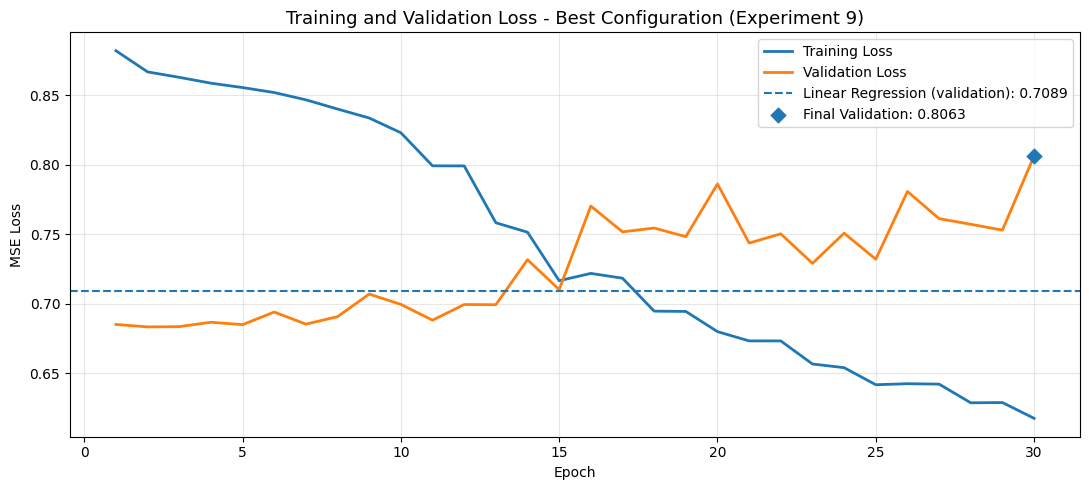

BEST CONFIGURATION: EXPERIMENT 9
--------------------------------
Final Training Loss: 0.6176
Final Validation Loss: 0.8063
Linear Regression Reference: 0.7089
Validation MSE (original scale): 5,330,863,104.00


In [364]:

# ==========================================
# FINAL LOSS CURVE - BEST CONFIGURATION
# ==========================================

import matplotlib.pyplot as plt
import numpy as np

# Use the best experiment (Experiment 7)
best_train_losses = exp7_train_losses
best_val_losses = exp7_val_losses

# Linear Regression validation loss
linear_reference = linear_val_losses[-1]

# Epoch numbers
epochs = range(1, len(best_train_losses) + 1)

# Create figure
plt.figure(figsize=(11, 5))

# Plot training loss
plt.plot(
    epochs,
    best_train_losses,
    label="Training Loss",
    linewidth=2
)

# Plot validation loss
plt.plot(
    epochs,
    best_val_losses,
    label="Validation Loss",
    linewidth=2
)

# Linear Regression reference line
plt.axhline(
    y=linear_reference,
    linestyle="--",
    linewidth=1.5,
    label=f"Linear Regression (validation): {linear_reference:.4f}"
)

# Mark final validation loss
plt.scatter(
    len(best_val_losses),
    best_val_losses[-1],
    marker="D",
    s=55,
    label=f"Final Validation: {best_val_losses[-1]:.4f}",
    zorder=5
)

# Titles and labels
plt.title(
    "Training and Validation Loss - Best Configuration (Experiment 9)",
    fontsize=13
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

# Legend and grid
plt.legend()
plt.grid(True, alpha=0.3)

plt.xticks(np.arange(0, 31, 5))

plt.tight_layout()
plt.show()

# Print final results
print("BEST CONFIGURATION: EXPERIMENT 9")
print("--------------------------------")
print(f"Final Training Loss: {best_train_losses[-1]:.4f}")
print(f"Final Validation Loss: {best_val_losses[-1]:.4f}")
print(f"Linear Regression Reference: {linear_reference:.4f}")
print(f"Validation MSE (original scale): {exp7_val_mse:,.2f}")
